# 2. PD model

Builds the probability of default (PD) model and its scorecard.

**Input:** `data/loan_data.pkl`.  
**Output:** PD predictions for each loan and the scorecard.

**2.1 Load the data  
2.2 Target and inputs  
2.3 Train/test split  
2.4 Prepare the inputs  
2.5 Model  
2.6 Evaluation  
2.7 Scorecard  
2.8 Save**

## 2.1 Load the data

We read `loan_data.pkl`, the table created in notebook 01, and check that it is the same table: the number of rows and columns and the default rate.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()
data_dir = '../data'  # relative to the notebooks folder

In [2]:
loan_data = pd.read_pickle(f'{data_dir}/loan_data.pkl')
loan_data.shape
# Expected output: (244967, 31)

(244967, 31)

In [3]:
loan_data['default'].mean()
# Expected output ~ 0.0575

np.float64(0.057493458302546874)

In [4]:
#loan_data.head()

## 2.2 Target and inputs

**Target.** The target is `default`: 1 if the loan defaulted, 0 otherwise. The model estimates the probability of default, PD = P(`default` = 1).

**Inputs.** The inputs are the loan and borrower characteristics known at origination. We exclude the following columns:

| Column | Reason |
|---|---|
| `default` | The target. |
| `loan_id` | Identifier of the loan; it does not describe the loan. |
| `zero_balance_code`, `zero_balance_removal_upb`, `actual_loss` | Known only when the loan closes, so they would leak the outcome. They are used in the LGD and EAD models. |
| `vintage`, `first_payment_date` | They identify the origination period. The model would learn the economic conditions of a period, not a characteristic of the borrower, and this does not carry over to new loans. |
| `maturity_date` | Equals `first_payment_date` plus `orig_loan_term`. It adds no information beyond the loan term. |
| `pre_harp_loan_id` | Identifier of the refinanced loan, filled only for HARP loans. The indicator `harp_indicator` already contains this information. |

In [5]:
input_cols = ['credit_score', 'first_time_homebuyer', 'msa', 'mi_pct', 'num_units',
              'occupancy_status', 'cltv', 'dti', 'orig_upb', 'ltv', 'int_rate',
              'channel', 'prepay_penalty', 'property_state', 'property_type',
              'postal_code', 'loan_purpose', 'orig_loan_term', 'num_borrowers',
              'seller_name', 'super_conforming', 'harp_indicator']
# The columns we keep as inputs

len(input_cols)

22

In [6]:
loan_data_inputs = loan_data[input_cols].copy()
loan_data_inputs.shape
#loan_data_inputs.head()

(244967, 22)

In [7]:
loan_data_targets = loan_data['default'].copy()
loan_data_targets.shape
#loan_data_targets.head()

(244967,)

In [8]:
loan_data_targets.mean()
# Expected output ~ 0.0575

np.float64(0.057493458302546874)

## 2.3 Train/test split

We split the loans randomly into a training set (80%) and a test set (20%). The model is fitted on the training set only. The test set is used once, at the end, to evaluate the model on loans it has not seen. The split is stratified by `default`, so both sets have the same default rate. The random seed is fixed so that the split is reproducible.

We split before preparing the inputs, so that nothing learned from the data in the next sections uses the test set.

In [9]:
from sklearn.model_selection import train_test_split

In [10]:
loan_data_inputs_train, loan_data_inputs_test, loan_data_targets_train, loan_data_targets_test = train_test_split(
    loan_data_inputs, loan_data_targets, test_size = 0.2, random_state = 42, stratify = loan_data_targets)
# We split the data

In [11]:
print(loan_data_inputs_train.shape, loan_data_inputs_test.shape)
print(loan_data_targets_train.shape, loan_data_targets_test.shape)
print(loan_data_targets_train.mean(), loan_data_targets_test.mean())

(195973, 22) (48994, 22)
(195973,) (48994,)
0.05749261377842866 0.05749683634730783


## 2.4 Prepare the inputs

All quantities learned from the data in this section (bins, weights of evidence) are computed on the training set only and then applied to the test set.

### 2.4.1 Missing values

We focus on the inputs with missing values. A scoring model must give a score to every loan, so we cannot drop loans with missing values; we have to handle them. For each variable we look at two quantities:

1. the number of loans with a missing value,
2. the default rate of these loans compared with the default rate of the loans without a missing value.

If the group of missing values is small, it cannot support a category of its own and is merged with a similar one. If the group is large, we further look at the default rates. If the default rates of the two groups differ enough, we consider the missing value to be informative and it forms a separate category. Otherwise, it is merged with a similar group.

In [12]:
df_inputs_prepr = loan_data_inputs_train.copy()
df_targets_prepr = loan_data_targets_train.copy()

In [13]:
cols_with_nulls = []
num_of_nulls = []

for col in input_cols:
    if df_inputs_prepr[col].isnull().sum() != 0:
        cols_with_nulls.append(col)
        num_of_nulls.append(df_inputs_prepr[col].isnull().sum())
        
default_rate_nulls = []
default_rate_notnulls = []

for col in cols_with_nulls:
    a = df_targets_prepr[df_inputs_prepr[col].isnull()].mean()
    b = df_targets_prepr[~df_inputs_prepr[col].isnull()].mean()
    default_rate_nulls.append(a)
    default_rate_notnulls.append(b)

missing_summary = pd.DataFrame({'num_of_nulls' : num_of_nulls, 
                                'default_rate_nulls' : default_rate_nulls,
                                'default_rate_notnulls' : default_rate_notnulls}, 
                                index = cols_with_nulls)
missing_summary

,num_of_nulls,default_rate_nulls,default_rate_notnulls
credit_score,124,0.048387,0.057498
first_time_homebuyer,44,0.000000,0.057506
msa,37590,0.052807,0.058605
mi_pct,2,0.000000,0.057493
cltv,14,0.000000,0.057497
dti,7973,0.051047,0.057766
ltv,13,0.000000,0.057496
property_type,1,0.000000,0.057493
postal_code,1,0.000000,0.057493
num_borrowers,65,0.000000,0.057512


**Remark.** 10 inputs have missing values in the training set.

- `msa` (19% of the loans): a missing value means that the property is outside a metropolitan area (or the area is unknown). This is information about the property, so the missing values form a separate category, regardless of the default rates.
- `dti` (4% of the loans): the default rate of the loans with a missing value (5.1%) is close to that of the other loans (5.8%) and the group is a small part of the sample, so it does not form a category of its own.
- The other 8 variables have at most 124 loans with missing values. These groups are too small to form a category of their own.

For these nine variables, the loans with missing values are merged into one of the other categories when we group the values (sections 2.4.2 and 2.4.3).

### 2.4.2 Discrete variables

For a discrete variable we group the loans by category. A *good* loan is a loan without default (`default` = 0) and a *bad* loan is a loan with default (`default` = 1). For the category $i$, let $n_{\text{good}}(i)$ and $n_{\text{bad}}(i)$ be the number of good and bad loans in it, respectively. Also, let $N_{\text{good}}$ and $N_{\text{bad}}$ be the number of good and bad loans in the whole training set, respectively.

The **weight of evidence** (WoE) of the category $i$ is defined by

$$\text{WoE}(i) = \ln \left( \frac{n_{\text{good}}(i) / N_{\text{good}}}{n_{\text{bad}}(i) / N_{\text{bad}}} \right).$$

It compares the share of all good loans that fall in the category with the share of all bad loans that fall in it.

- $\text{WoE}(i) > 0$: the category contains a larger share of the good loans than of the bad loans. It is safer than the average.
- $\text{WoE}(i) < 0$: the category contains a larger share of the bad loans. It is riskier than the average.
- $\text{WoE}(i) = 0$: the category does not separate good from bad loans.

Equivalently, $\text{WoE}$ is the logarithm of the ratio between the odds good:bad in the category, $n_{\text{good}}(i) / n_{\text{bad}}(i)$, and the odds in the whole sample, $N_{\text{good}} / N_{\text{bad}}$. It is undefined when a category has no good or no bad loans.

The **information value** (IV) of the variable is defined by

$$\text{IV} = \sum_i \left( \frac{n_{\text{good}}(i)}{N_{\text{good}}} - \frac{n_{\text{bad}}(i)}{N_{\text{bad}}} \right) \text{WoE}(i)$$

where the sum is taken over all categories of the variable.

**Remarks on the formula.**

- We want to compare the distribution of the variable among the good loans with its distribution among the bad loans, so in each category we subtract: *share of good loans − share of bad loans*.
- The logarithm $\ln\frac{n_{\text{good}}(i)/N_{\text{good}}}{n_{\text{bad}}(i)/N_{\text{bad}}}$ is the weight of evidence. It measures the (logarithmic) relative difference between the two shares. It is $0$ if the shares are equal, positive if the category has a larger share of good loans and negative if it has a larger share of bad loans.
- The relative difference matters: the same absolute gap is more informative in a small category than in a large one. *E.g. shares $10\%$ and $5\%$: $0.05\cdot\ln 2\approx 0.035$; shares $50\%$ and $45\%$: $0.05\cdot\ln\frac{0.50}{0.45}\approx 0.005$.*
- Thus the IV is the sum, over all categories of the variable, of the differences of the shares weighted by their relative difference.
- The factors $\left(\frac{n_{\text{good}}(i)}{N_{\text{good}}}-\frac{n_{\text{bad}}(i)}{N_{\text{bad}}}\right)$ and $\text{WoE}(i)$ always have the same sign, so every term is non-negative and $\text{IV}\ge 0$. It is $0$ exactly when the two distributions coincide, that is, when the variable does not separate good from bad loans.

**Procedure.** We apply the same steps to each discrete variable:

1. **Table.** The function `woe_discrete` returns, for each category, the number of loans, the default rate, the weight of evidence (WoE), the differences of the default rate and of the WoE between consecutive categories (after sorting by WoE), and the information value (IV) of the variable.
2. **Plot.** The function `plot_by_woe` shows the WoE of the categories, sorted from the riskiest to the safest.
3. **Grouping.** We merge values that cannot be told apart into categories, so that every category is large enough to give a reliable default rate and the categories differ clearly in risk. We merge:
    - values with less than 5% of the loans, or with no or very few defaults,
    - consecutive values with a small difference in WoE,
    - the loans with a missing value, as decided in section 2.4.1.


    Merged values must also make sense together, i.e. describe similar situations and not only have close WoE by chance. For ordinal variables (e.g. `num_units`, `num_borrowers`), the WoE of the categories should be monotonic, as far as possible; for nominal variables (e.g. `channel`, `property_state`) the order of the values is arbitrary and this does not apply.
4. **Dummy variables.** Each final category becomes a dummy variable (1 if the loan belongs to the category, 0 otherwise). One category of each variable is left out as the reference category: the dummies of a variable sum to 1, the intercept column, so including all of them would cause perfect multicollinearity. As reference category we choose the category with the lowest WoE (the riskiest one), so that every coefficient is interpreted relative to the riskiest category of its variable.
5. **Selection.** A variable whose information value is below $0.02$ is considered not predictive and is excluded from the model. The usual rule of thumb is: $\text{IV} < 0.02$ not predictive, $0.02$–$0.1$ weak, $0.1$–$0.3$ medium, $0.3$–$0.5$ strong, and $\text{IV} > 0.5$ suspiciously strong (possible leakage of information from the target). Merging categories never increases the IV (this follows from the log-sum inequality, a consequence of Jensen's inequality). Hence, if the IV of the variable is below 0.02 before merging, it is also below 0.02 after any merge, and we drop the variable. Otherwise, we merge the categories and compute the IV again on the final categories.

All tables and groupings are computed on the training set only.

In [14]:
def woe_discrete(df, variable_name, targets):
    data = pd.concat([df[variable_name], targets.rename('default')], axis = 1)
    table = data.groupby(variable_name, dropna = False).agg(n_obs = ('default', 'count'),
                                                           n_bad = ('default', 'sum'))
    table['n_good'] = table['n_obs'] - table['n_bad']
    table['prop_n_obs'] = table['n_obs'] / table['n_obs'].sum()
    table['prop_n_bad'] = table['n_bad'] / table['n_bad'].sum()
    table['prop_n_good'] = table['n_good'] / table['n_good'].sum()
    table['WoE'] = np.log(table['prop_n_good'] / table['prop_n_bad'])
    table = table.sort_values('WoE').reset_index()
    table['diff_WoE'] = table['WoE'].diff().abs()
    table['default_rate'] = table['n_bad'] / table['n_obs']
    table['diff_default_rate'] = table['default_rate'].diff().abs()
    table['IV'] = ((table['prop_n_good'] - table['prop_n_bad']) * table['WoE']).sum()
    return table

In [15]:
def plot_by_woe(table, rotation = 0):
    x = table.iloc[:, 0].astype(object).fillna('missing').astype(str)
    plt.figure(figsize = (10, 4))
    plt.plot(x, table['WoE'], marker = 'o', linestyle = '--', color = 'k')
    plt.xlabel(table.columns[0])
    plt.ylabel('Weight of evidence')
    plt.title('Weight of evidence by ' + table.columns[0])
    plt.xticks(rotation = rotation)
    plt.show()

In [16]:
ref_categories = {}
# For each discrete input variable, we store the reference category

#### 1. `first_time_homebuyer`

In [17]:
first_time_homebuyer_table = woe_discrete(df_inputs_prepr, 'first_time_homebuyer', df_targets_prepr)
first_time_homebuyer_table

,first_time_homebuyer,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,Y,19129,1347,17782,0.097610,0.119553,0.096272,-0.216580,NaN,0.070417,NaN,inf
1,N,176800,9920,166880,0.902165,0.880447,0.903490,0.025835,0.242415,0.056109,0.014308,inf
2,NaN,44,0,44,0.000225,0.000000,0.000238,inf,inf,0.000000,0.056109,inf


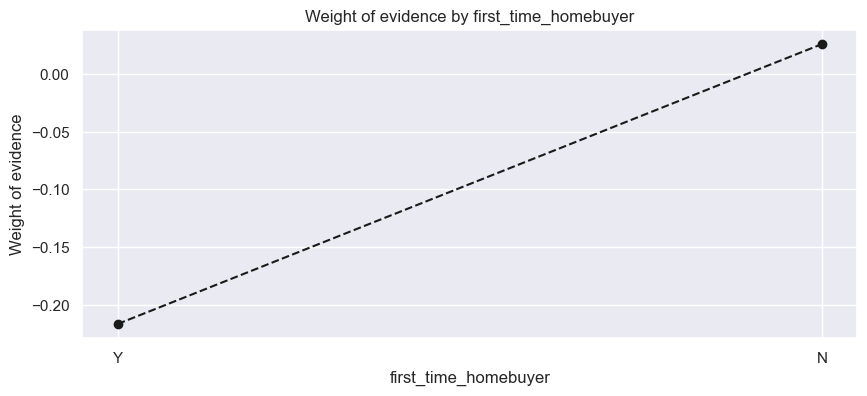

In [18]:
plot_by_woe(first_time_homebuyer_table)

- First-time homebuyers (`Y`) default more often (7.0%) than the others (5.6%), so the two categories are kept separate.
- The 44 loans with a missing value are too few to form a category and are merged with the largest one, `N`, because this changes the category the least.

In [19]:
# We set missing values as `N`.
df_inputs_prepr['first_time_homebuyer'] = df_inputs_prepr['first_time_homebuyer'].fillna('N')

In [20]:
# We look again at the IV
first_time_homebuyer_table = woe_discrete(df_inputs_prepr, 'first_time_homebuyer', df_targets_prepr)
first_time_homebuyer_table

,first_time_homebuyer,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,Y,19129,1347,17782,0.09761,0.119553,0.096272,-0.216580,NaN,0.070417,NaN,0.00565
1,N,176844,9920,166924,0.90239,0.880447,0.903728,0.026098,0.242679,0.056095,0.014322,0.00565


**Remark.** Since after merging $\text{IV} \approx 0.006$, below the threshold of $0.02$, the variable `first_time_homebuyer` is excluded from the model. We create no dummy variables for it and add no entry to `ref_categories`.

#### 2. `num_units`

In [21]:
num_units_table = woe_discrete(df_inputs_prepr, 'num_units', df_targets_prepr)
num_units_table

,num_units,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,2.0,3040,246,2794,0.015512,0.021834,0.015127,-0.366989,NaN,0.080921,NaN,0.002706
1,3.0,486,35,451,0.002480,0.003106,0.002442,-0.240768,0.126221,0.072016,0.008905,0.002706
2,4.0,425,27,398,0.002169,0.002396,0.002155,-0.106272,0.134496,0.063529,0.008487,0.002706
3,1.0,192022,10959,181063,0.979839,0.972664,0.980277,0.007797,0.114069,0.057072,0.006458,0.002706


C:\Users\keram\AppData\Local\Temp\ipykernel_9292\3094246576.py:2: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  x = table.iloc[:, 0].astype(object).fillna('missing').astype(str)


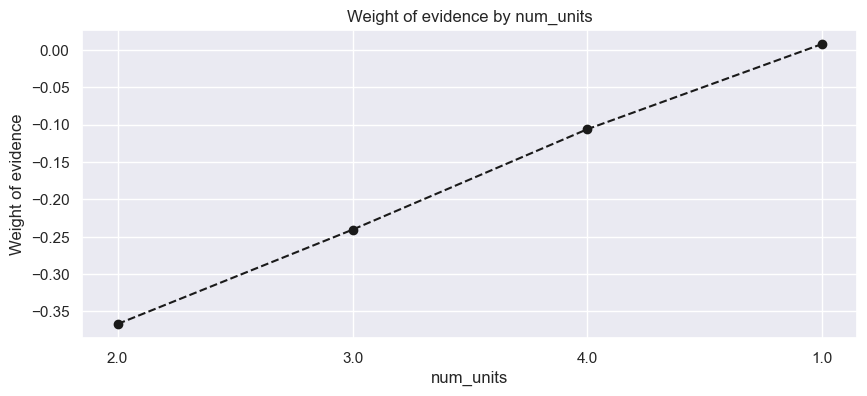

In [22]:
plot_by_woe(num_units_table)

**Remark.** Since $\text{IV} \approx 0.003$, below the threshold of $0.02$, the variable `num_units` is excluded from the model. We create no dummy variables for it and add no entry to `ref_categories`.

#### 3. `occupancy_status`

In [23]:
occupancy_status_table = woe_discrete(df_inputs_prepr, 'occupancy_status', df_targets_prepr)
occupancy_status_table

,occupancy_status,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,I,10278,935,9343,0.052446,0.082986,0.050583,-0.495051,NaN,0.090971,NaN,0.01722
1,S,9960,571,9389,0.050823,0.050679,0.050832,0.003018,0.498069,0.057329,0.033642,0.01722
2,P,175735,9761,165974,0.896731,0.866335,0.898585,0.036549,0.033531,0.055544,0.001785,0.01722


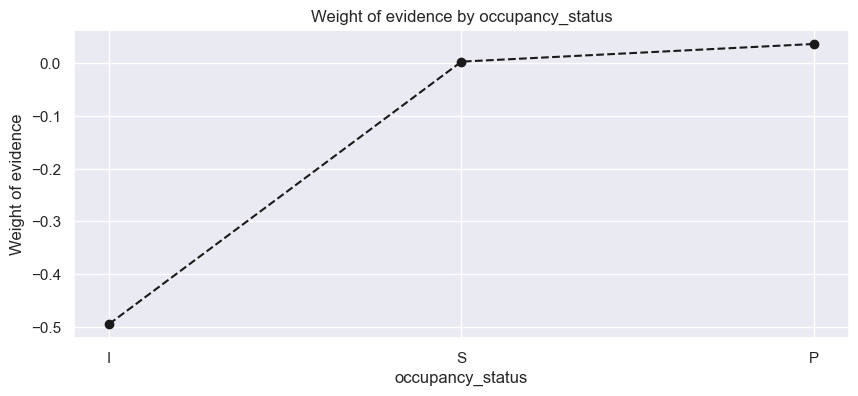

In [24]:
plot_by_woe(occupancy_status_table)

**Remark.** There are no missing values. The IV of the two categories is $\approx 0.0172 < 0.02$, and since merging categories never increases the IV, it stays below $0.02$ for any grouping. Hence `occupancy_status` is dropped from the model. We create no dummy variables for it and add no entry to `ref_categories`.

#### 4. `channel`

In [25]:
channel_table = woe_discrete(df_inputs_prepr, 'channel', df_targets_prepr)
channel_table

,channel,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,T,71662,6296,65366,0.365673,0.558800,0.353892,-0.456800,NaN,0.087857,NaN,0.204479
1,R,95317,4230,91087,0.486378,0.375433,0.493146,0.272726,0.729525,0.044378,0.043479,0.204479
2,B,11004,359,10645,0.056151,0.031863,0.057632,0.592636,0.319910,0.032625,0.011754,0.204479
3,C,17990,382,17608,0.091798,0.033904,0.095330,1.033801,0.441165,0.021234,0.011390,0.204479


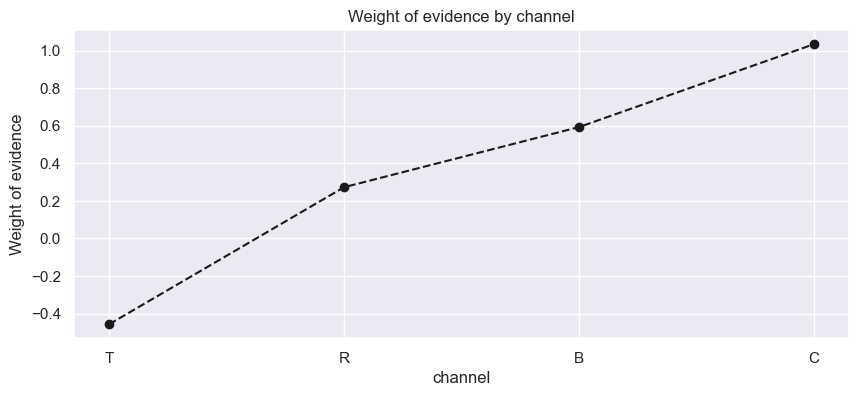

In [26]:
plot_by_woe(channel_table)

**Remark.** There are no missing values. All four categories are large and their default rates differ clearly, so no categories are merged. $\text{IV} \approx 0.204 > 0.02$, hence `channel` is kept. The reference category is `T`, the one with the lowest WoE.

In [27]:
# Add the first reference category on the dictionary
ref_categories['channel'] = 'channel:T'

In [28]:
# Create the dummies
categories = ['T', 'R', 'B', 'C']
for category in categories:
    df_inputs_prepr[f'channel:{category}'] = np.where((df_inputs_prepr['channel'] == category), 1, 0)

In [29]:
df_inputs_prepr[['channel:T', 'channel:R', 'channel:B', 'channel:C']].sum(axis = 1).value_counts()
# Expected output: 1 for all 195973 loans

1    195973
Name: count, dtype: int64

#### 5. `prepay_penalty`

In [30]:
prepay_penalty_table = woe_discrete(df_inputs_prepr, 'prepay_penalty', df_targets_prepr)
prepay_penalty_table

,prepay_penalty,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,Y,192,23,169,0.00098,0.002041,0.000915,-0.802483,NaN,0.119792,NaN,0.000905
1,N,195781,11244,184537,0.99902,0.997959,0.999085,0.001128,0.803611,0.057432,0.06236,0.000905


**Remark.** There are no missing values. SInce $\text{IV} \approx 0.001 < 0.02$, `prepay_penalty` is dropped from the model. We create no dummy variables for it and add no entry to `ref_categories`.

#### 6. `property_state`

In [31]:
property_state_table = woe_discrete(df_inputs_prepr, 'property_state', df_targets_prepr)
property_state_table

,property_state,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,NV,1703,321,1382,0.008690,0.028490,0.007482,-1.337041,NaN,0.188491,NaN,inf
1,FL,10923,1695,9228,0.055737,0.150439,0.049960,-1.102328,0.234714,0.155177,0.033314,inf
2,AZ,5336,756,4580,0.027228,0.067099,0.024796,-0.995474,0.106853,0.141679,0.013498,inf
3,MI,6598,604,5994,0.033668,0.053608,0.032452,-0.501947,0.493527,0.091543,0.050136,inf
4,GA,5947,492,5455,0.030346,0.043667,0.029533,-0.391078,0.110869,0.082731,0.008812,inf
5,RI,700,57,643,0.003572,0.005059,0.003481,-0.373794,0.017284,0.081429,0.001302,inf
6,MS,838,57,781,0.004276,0.005059,0.004228,-0.179363,0.194430,0.068019,0.013409,inf
7,ID,1485,96,1389,0.007578,0.008520,0.007520,-0.124896,0.054467,0.064646,0.003373,inf
8,IL,10743,671,10072,0.054819,0.059554,0.054530,-0.088142,0.036754,0.062459,0.002187,inf
9,CA,18247,1137,17110,0.093110,0.100914,0.092634,-0.085617,0.002524,0.062312,0.000148,inf


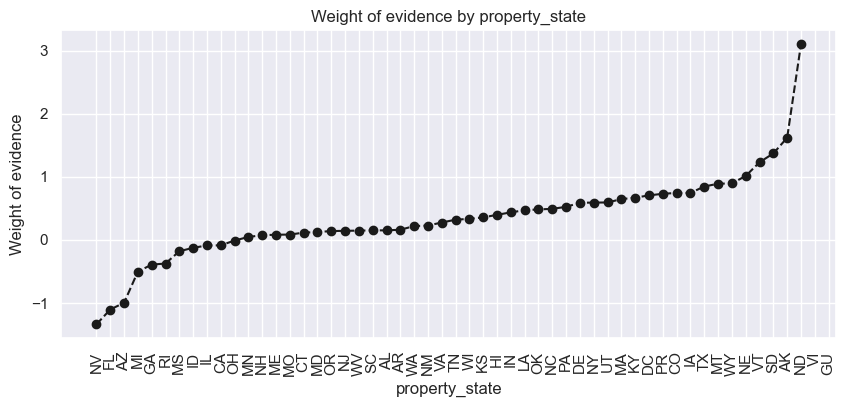

In [32]:
plot_by_woe(property_state_table, rotation = 90)

`property_state` has 54 values (states), and only four of them contain more than 5% of the loans. Moreover, `VI` and `GU` contain no defaults, so their WoE is not defined and the IV cannot be computed before merging. We therefore merge the states before computing the IV. The categories are sets of consecutive states in the order of the WoE, so that states with a similar risk are merged. Each category contains at least 5% of the loans, so that its default rate is reliable. The boundaries are placed where the WoE jumps and, where it grows gradually, as soon as the category reaches 5% of the loans. `VI` and `GU` are merged into the category with the highest WoE.

In [33]:
property_state_table['cum_prop_n_obs'] = property_state_table['prop_n_obs'].cumsum()
property_state_table[['property_state', 'prop_n_obs', 'cum_prop_n_obs', 'WoE', 'diff_WoE']]

,property_state,prop_n_obs,cum_prop_n_obs,WoE,diff_WoE
0,NV,0.008690,0.008690,-1.337041,NaN
1,FL,0.055737,0.064427,-1.102328,0.234714
2,AZ,0.027228,0.091655,-0.995474,0.106853
3,MI,0.033668,0.125323,-0.501947,0.493527
4,GA,0.030346,0.155669,-0.391078,0.110869
5,RI,0.003572,0.159241,-0.373794,0.017284
6,MS,0.004276,0.163517,-0.179363,0.194430
7,ID,0.007578,0.171095,-0.124896,0.054467
8,IL,0.054819,0.225914,-0.088142,0.036754
9,CA,0.093110,0.319024,-0.085617,0.002524


- First category: `NV`, `FL`, `AZ`. Their WoE is similar (from $-1.34$ to $-1.00$) and there is a clear gap between `AZ` and the next value, `MI`.
- Second category: `MI`, `GA`, `RI`. Same reason: similar WoE (from $-0.50$ to $-0.37$) and a gap before the next value, `MS`.
- `VI` and `GU` are too small and contain no defaults, so their WoE is not defined. We merge them with the last category, when we form it.
- We leave these eight states out of the plot below, to see the differences between the remaining ones more clearly. This only affects the plot; the data are not changed.

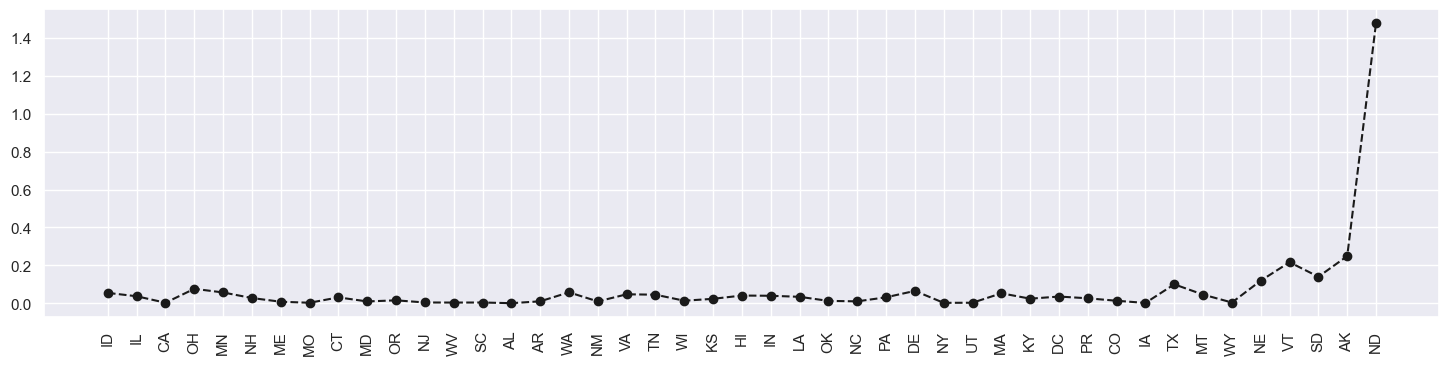

In [34]:
middle = property_state_table.iloc[6:52]
# The states between the first two categories and the last (VI, GU)

plt.figure(figsize = (18, 4))
plt.plot(middle['property_state'].iloc[1:], middle['diff_WoE'].iloc[1:], marker = 'o', linestyle = '--', color = 'k')
plt.xticks(rotation = 90)
plt.show()

Final categories:

| Category | States | Loans |
|---|---|---|
| 1 | `NV`, `FL`, `AZ` | 9.2% |
| 2 | `MI`, `GA`, `RI` | 6.8% |
| 3 | `MS`, `ID`, `IL`, `CA` | 16.0% |
| 4 | `OH`, `MN`, `NH`, `ME`, `MO`, `CT`, `MD`, `OR`, `NJ`, `WV`, `SC`, `AL`, `AR` | 22.1% |
| 5 | `WA`, `NM`, `VA`, `TN`, `WI`, `KS`, `HI`, `IN`, `LA`, `OK`, `NC`, `PA`, `DE` | 24.9% |
| 6 | `NY`, `UT`, `MA`, `KY`, `DC`, `PR`, `CO`, `IA` | 12.9% |
| 7 | `TX`, `MT`, `WY`, `NE`, `VT`, `SD`, `AK`, `ND`, `VI`, `GU` | 8.1% |

- In categories 1–6 the WoE of the states differs by at most $0.37$. The boundaries between categories 1 and 2, and between 2 and 3, are at clear jumps of the WoE. Elsewhere the WoE grows gradually and the boundaries are placed so that each category has at least 5% of the loans and the WoE inside it varies little.
- Category 7 contains the safest states. `NE`, `VT`, `SD`, `AK`, `ND`, `VI` and `GU` are too small (together 1.7% of the loans) and have too few defaults for a reliable WoE (`VI` and `GU` have none), so they are merged with `TX`, `MT` and `WY`.

In [35]:
# Create the dummies
property_state_groups = {
    1: ['NV', 'FL', 'AZ'],
    2: ['MI', 'GA', 'RI'],
    3: ['MS', 'ID', 'IL', 'CA'],
    4: ['OH', 'MN', 'NH', 'ME', 'MO', 'CT', 'MD', 'OR', 'NJ', 'WV', 'SC', 'AL', 'AR'],
    5: ['WA', 'NM', 'VA', 'TN', 'WI', 'KS', 'HI', 'IN', 'LA', 'OK', 'NC', 'PA', 'DE'],
    6: ['NY', 'UT', 'MA', 'KY', 'DC', 'PR', 'CO', 'IA'],
    7: ['TX', 'MT', 'WY', 'NE', 'VT', 'SD', 'AK', 'ND', 'VI', 'GU']}
# The categories of property_state, with the states they contain

for category, states in property_state_groups.items():
    df_inputs_prepr[f'property_state:{category}'] = np.where(df_inputs_prepr['property_state'].isin(states), 1, 0)

dummy_cols = [f'property_state:{i}' for i in range(1, 8)]
df_inputs_prepr[dummy_cols].sum(axis = 1).value_counts()
# Expected output: 1 for all 195973 loans

1    195973
Name: count, dtype: int64

In [36]:
# Check the IV
property_state_grouped = df_inputs_prepr[dummy_cols].idxmax(axis = 1).to_frame('property_state')
property_state_table_grouped = woe_discrete(property_state_grouped, 'property_state', df_targets_prepr)
property_state_table_grouped

,property_state,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,property_state:1,17962,2772,15190,0.091655,0.246028,0.082239,-1.095819,NaN,0.154326,NaN,0.31978
1,property_state:2,13245,1153,12092,0.067586,0.102334,0.065466,-0.446710,0.649109,0.087052,0.067274,0.31978
2,property_state:3,31313,1961,29352,0.159782,0.174048,0.158912,-0.090981,0.355729,0.062626,0.024426,0.31978
3,property_state:4,43224,2273,40951,0.220561,0.201740,0.221709,0.094388,0.185370,0.052587,0.010039,0.31978
4,property_state:5,48894,1955,46939,0.249494,0.173516,0.254128,0.381571,0.287183,0.039984,0.012602,0.31978
5,property_state:6,25374,780,24594,0.129477,0.069229,0.133152,0.654077,0.272505,0.030740,0.009244,0.31978
6,property_state:7,15961,373,15588,0.081445,0.033106,0.084394,0.935791,0.281714,0.023369,0.007371,0.31978


**Remark.** There are no missing values. The 54 states are merged into 7 categories (table above). After merging, $\text{IV} \approx 0.320 > 0.02$, and the WoE increases from category 1 to category 7. Hence `property_state` is kept. The reference category is category 1, the one with the lowest WoE.

In [37]:
ref_categories['property_state'] = 'property_state:1'
# Add the reference category

#### 7. `property_type`

In [38]:
property_type_table = woe_discrete(df_inputs_prepr, 'property_type', df_targets_prepr)
property_type_table

,property_type,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,MH,1824,223,1601,0.009307,0.019792,0.008668,-0.825675,NaN,0.122259,NaN,inf
1,CO,14688,1236,13452,0.074949,0.109701,0.072829,-0.409640,0.416035,0.084150,0.038108,inf
2,SF,148038,8192,139846,0.755400,0.727079,0.757128,0.040496,0.450136,0.055337,0.028813,inf
3,PU,30776,1604,29172,0.157042,0.142363,0.157937,0.103822,0.063325,0.052119,0.003219,inf
4,CP,646,12,634,0.003296,0.001065,0.003432,1.170255,1.066433,0.018576,0.033543,inf
5,NaN,1,0,1,0.000005,0.000000,0.000005,inf,inf,0.000000,0.018576,inf


Only one loan has a missing value, and it does not default, so it gives no information about the risk. We merge it with the largest category, `SF`, because this changes the category the least.

In [39]:
df_inputs_prepr['property_type'] = df_inputs_prepr['property_type'].fillna('SF')
property_type_table = woe_discrete(df_inputs_prepr, 'property_type', df_targets_prepr)
property_type_table

,property_type,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,MH,1824,223,1601,0.009307,0.019792,0.008668,-0.825675,NaN,0.122259,NaN,0.029894
1,CO,14688,1236,13452,0.074949,0.109701,0.072829,-0.409640,0.416035,0.084150,0.038108,0.029894
2,SF,148039,8192,139847,0.755405,0.727079,0.757133,0.040504,0.450143,0.055337,0.028814,0.029894
3,PU,30776,1604,29172,0.157042,0.142363,0.157937,0.103822,0.063318,0.052119,0.003218,0.029894
4,CP,646,12,634,0.003296,0.001065,0.003432,1.170255,1.066433,0.018576,0.033543,0.029894


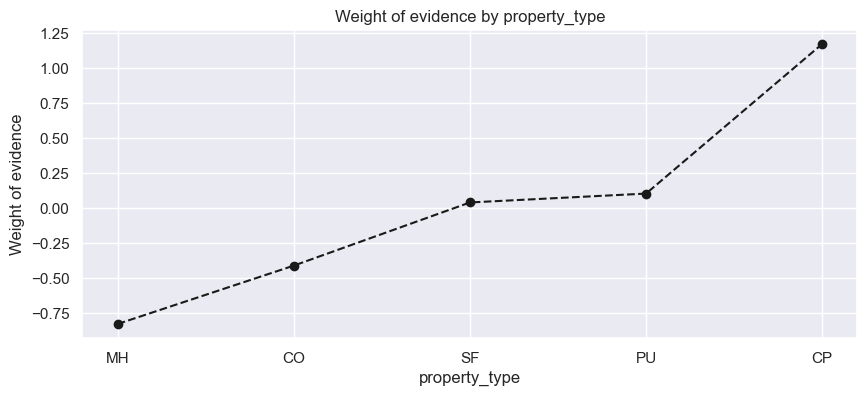

In [40]:
plot_by_woe(property_type_table)

- `MH` and `CO` are merged: both are riskier than average (WoE $-0.83$ and $-0.41$). Together they contain 8.4% of the loans.
- `SF` is the largest category (75.5% of the loans) and stays alone. It also contains the one loan with a missing value.
- `PU` and `CP` are merged: `CP` has only 0.3% of the loans and 12 defaults, so its default rate is unreliable. Together they contain 16.0% of the loans.

In [41]:
# Create the dummies
property_type_groups = {
    'MH_CO': ['MH', 'CO'],
    'SF': ['SF'],
    'PU_CP': ['PU', 'CP']}
# The categories of property_type, with the values they contain

for category, values in property_type_groups.items():
    df_inputs_prepr[f'property_type:{category}'] = np.where(df_inputs_prepr['property_type'].isin(values), 1, 0)

dummy_cols = [f'property_type:{category}' for category in property_type_groups]
df_inputs_prepr[dummy_cols].sum(axis = 1).value_counts()
# Expected output: 1 for all 195973 loans

1    195973
Name: count, dtype: int64

In [42]:
property_type_grouped = df_inputs_prepr[dummy_cols].idxmax(axis = 1).to_frame('property_type')
property_type_table_grouped = woe_discrete(property_type_grouped, 'property_type', df_targets_prepr)
property_type_table_grouped

,property_type,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,property_type:MH_CO,16512,1459,15053,0.084257,0.129493,0.081497,-0.463061,NaN,0.088360,NaN,0.025557
1,property_type:SF,148039,8192,139847,0.755405,0.727079,0.757133,0.040504,0.503565,0.055337,0.033023,0.025557
2,property_type:PU_CP,31422,1616,29806,0.160338,0.143428,0.161370,0.117868,0.077365,0.051429,0.003908,0.025557


**Remark.** After merging, $\text{IV} \approx 0.026 > 0.02$, so `property_type` is kept as a weak predictor. The WoE increases from `MH_CO` to `PU_CP`. The reference category is `MH_CO`, the one with the lowest WoE.

In [43]:
ref_categories['property_type'] = 'property_type:MH_CO'

#### 8. `loan_purpose`

In [44]:
loan_purpose_table = woe_discrete(df_inputs_prepr, 'loan_purpose', df_targets_prepr)
loan_purpose_table

,loan_purpose,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,C,66634,4413,62221,0.340016,0.391675,0.336865,-0.150749,NaN,0.066227,NaN,0.019844
1,P,75713,4341,71372,0.386344,0.385284,0.386409,0.002914,0.153663,0.057335,0.008893,0.019844
2,N,53626,2513,51113,0.273640,0.223041,0.276726,0.215674,0.212761,0.046862,0.010473,0.019844


**Remark.** There are no missing values. $\text{IV} \approx 0.0198 < 0.02$, so `loan_purpose` is dropped from the model, although it is close to the threshold. We create no dummy variables for it and add no entry to `ref_categories`.

#### 9. `num_borrowers`

In [45]:
num_borrowers_table = woe_discrete(df_inputs_prepr, 'num_borrowers', df_targets_prepr)
num_borrowers_table

,num_borrowers,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,1.0,85549,6771,78778,0.436535,0.600959,0.426505,-0.342902,NaN,0.079148,NaN,inf
1,2.0,110359,4496,105863,0.563134,0.399041,0.573143,0.362070,0.704973,0.040740,0.038408,inf
2,NaN,65,0,65,0.000332,0.000000,0.000352,inf,inf,0.000000,0.040740,inf


The 65 loans with a missing value are too few to form a category and are merged with the largest one, `2.0`, because this changes the category the least.

In [46]:
df_inputs_prepr['num_borrowers'] = df_inputs_prepr['num_borrowers'].fillna(2.0)

num_borrowers_table = woe_discrete(df_inputs_prepr, 'num_borrowers', df_targets_prepr)
num_borrowers_table

,num_borrowers,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,1.0,85549,6771,78778,0.436535,0.600959,0.426505,-0.342902,NaN,0.079148,NaN,0.123092
1,2.0,110424,4496,105928,0.563465,0.399041,0.573495,0.362684,0.705587,0.040716,0.038432,0.123092


**Remark.** After merging the missing values, $\text{IV} \approx 0.123 > 0.02$, so `num_borrowers` is kept as a medium predictor. The two categories are large and their default rates differ clearly (7.9% for one borrower, 4.1% for two), so no further categories are merged. The reference category is `1`, the one with the lowest WoE.

In [47]:
# Create the dummies
for category in [1, 2]:
    df_inputs_prepr[f'num_borrowers:{category}'] = np.where(df_inputs_prepr['num_borrowers'] == category, 1, 0)

df_inputs_prepr[['num_borrowers:1', 'num_borrowers:2']].sum(axis = 1).value_counts()
# Expected output: 1 for all 195973 loans

1    195973
Name: count, dtype: int64

In [48]:
ref_categories['num_borrowers'] = 'num_borrowers:1'

#### 10. `seller_name`

In [49]:
seller_name_table = woe_discrete(df_inputs_prepr, 'seller_name', df_targets_prepr)
seller_name_table

,seller_name,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,"COUNTRYWIDE HOME LOANS, INC.",12393,1487,10906,0.063238,0.131978,0.059045,-0.804335,NaN,0.119987,NaN,inf
1,GMAC MORTGAGE CORPORATION,2896,280,2616,0.014778,0.024851,0.014163,-0.562275,0.242060,0.096685,0.023302,inf
2,"COUNTRYWIDE BANK, FSB",1871,162,1709,0.009547,0.014378,0.009253,-0.440820,0.121455,0.086585,0.010100,inf
3,"TAYLOR, BEAN & WHITAKER MORTGAGE CORP.",7160,600,6560,0.036536,0.053253,0.035516,-0.405071,0.035749,0.083799,0.002786,inf
4,FIRST HORIZON HOME LOAN CORPORATION,144,12,132,0.000735,0.001065,0.000715,-0.398992,0.006079,0.083333,0.000466,inf
5,"GMAC MORTGAGE, LLC",3755,300,3455,0.019161,0.026626,0.018705,-0.353092,0.045900,0.079893,0.003440,inf
6,"FLAGSTAR BANK, FSB",1247,97,1150,0.006363,0.008609,0.006226,-0.324081,0.029011,0.077787,0.002107,inf
7,"SUNTRUST MORTGAGE, INC.",1542,119,1423,0.007868,0.010562,0.007704,-0.315488,0.008593,0.077173,0.000614,inf
8,WASHINGTON MUTUAL BANK,8694,628,8066,0.044363,0.055738,0.043669,-0.244014,0.071474,0.072234,0.004939,inf
9,NATIONAL CITY MORTGAGE CO.,2386,167,2219,0.012175,0.014822,0.012014,-0.210069,0.033945,0.069992,0.002242,inf


**Remark.** `seller_name` is excluded from the model, without computing its IV. The variable identifies the institution that delivered the loan, and its relation to default comes from specific institutions in the 2005–2009 sample, many of which no longer exist. A new loan cannot have these values, and for a seller not present in the sample the model would have no category. As in the case of `vintage` (section 2.2), the model would learn a feature of the period and not a characteristic of the loan. We create no dummy variables for it and add no entry to `ref_categories`.

#### 11. `super_conforming`

In [50]:
super_conforming_table = woe_discrete(df_inputs_prepr, 'super_conforming', df_targets_prepr)
super_conforming_table

,super_conforming,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,N,195102,11266,183836,0.995556,0.999911,0.99529,-0.004633,NaN,0.057744,NaN,0.018376
1,Y,871,1,870,0.004444,0.000089,0.00471,3.971606,3.976238,0.001148,0.056596,0.018376


**Remark.** There are no missing values. $\text{IV} \approx 0.018 < 0.02$, so `super_conforming` is dropped from the model. Moreover, the category `Y` contains 871 loans with a single default, so its WoE is unreliable. We create no dummy variables for it and add no entry to `ref_categories`.

#### 12. `harp_indicator`

In [51]:
harp_indicator_table = woe_discrete(df_inputs_prepr, 'harp_indicator', df_targets_prepr)
harp_indicator_table

,harp_indicator,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,N,191760,11095,180665,0.978502,0.984734,0.978122,-0.006737,NaN,0.057859,NaN,0.002424
1,Y,4213,172,4041,0.021498,0.015266,0.021878,0.359866,0.366603,0.040826,0.017033,0.002424


**Remark.** There are no missing values. $\text{IV} \approx 0.002 < 0.02$, so `harp_indicator` is dropped from the model. We create no dummy variables for it and add no entry to `ref_categories`.

#### 12. `msa` and `postal_code`

In [52]:
df_inputs_prepr[['msa', 'postal_code']].nunique()

msa            450
postal_code    888
dtype: int64

**Remark.** `msa` and `postal_code` have 450 and 888 distinct values, respectively, which gives on average only about 20 and 12 defaults per value. The WoE of such small categories is mostly noise, so grouping the values by their WoE would produce groups that separate good from bad loans in the training set but not in new data. The geographic information is already contained in `property_state`. Hence both variables are excluded from the model. We create no dummy variables for them and add no entry to `ref_categories`. A more careful grouping of such variables (e.g. one that takes into account the number of defaults of each value) is a possible extension.

### 2.4.3 Continuous variables

A continuous variable is handled in two steps. First, we split its range into 50 intervals of equal width (*fine classing*) and compute the WoE of each interval. Then, we merge consecutive intervals with a similar WoE into a few final categories (*coarse classing*). The intervals are ordered by the value of the variable, not by their WoE, since only consecutive intervals can be merged. The boundaries of the final categories are determined on the training set and applied unchanged to the test set. As before, a variable is dropped if the IV of its final categories is below $0.02$.

In [53]:
def woe_ordered(df, variable_name, targets):
    data = pd.concat([df[variable_name], targets.rename('default')], axis = 1)
    table = data.groupby(variable_name, dropna = False, observed = True).agg(n_obs = ('default', 'count'),
                                                                              n_bad = ('default', 'sum'))
    table['n_good'] = table['n_obs'] - table['n_bad']
    table['prop_n_obs'] = table['n_obs'] / table['n_obs'].sum()
    table['prop_n_bad'] = table['n_bad'] / table['n_bad'].sum()
    table['prop_n_good'] = table['n_good'] / table['n_good'].sum()
    table['WoE'] = np.log(table['prop_n_good'] / table['prop_n_bad'])
    table = table.reset_index()
    table['diff_WoE'] = table['WoE'].diff().abs()
    table['default_rate'] = table['n_bad'] / table['n_obs']
    table['diff_default_rate'] = table['default_rate'].diff().abs()
    table['IV'] = ((table['prop_n_good'] - table['prop_n_bad']) * table['WoE']).sum()
    return table

#### 1. `credit_score`

In [54]:
credit_score_fine = pd.cut(df_inputs_prepr['credit_score'], 50).to_frame('credit_score')
credit_score_table = woe_ordered(credit_score_fine, 'credit_score', df_targets_prepr)
credit_score_table

C:\Users\keram\anaconda3\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


,credit_score,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,"(299.456, 310.88]",91,5,86,0.000464,0.000444,0.000466,0.048022,NaN,0.054945,NaN,inf
1,"(376.16, 387.04]",2,0,2,0.000010,0.000000,0.000011,inf,inf,0.000000,0.054945,inf
2,"(419.68, 430.56]",1,1,0,0.000005,0.000089,0.000000,-inf,inf,1.000000,1.000000,inf
3,"(441.44, 452.32]",2,0,2,0.000010,0.000000,0.000011,inf,inf,0.000000,1.000000,inf
4,"(463.2, 474.08]",1,0,1,0.000005,0.000000,0.000005,inf,NaN,0.000000,0.000000,inf
5,"(474.08, 484.96]",5,1,4,0.000026,0.000089,0.000022,-1.410593,inf,0.200000,0.200000,inf
6,"(484.96, 495.84]",7,1,6,0.000036,0.000089,0.000032,-1.005128,0.405465,0.142857,0.057143,inf
7,"(495.84, 506.72]",14,1,13,0.000071,0.000089,0.000070,-0.231938,0.773190,0.071429,0.071429,inf
8,"(506.72, 517.6]",23,5,18,0.000117,0.000444,0.000097,-1.515953,1.284016,0.217391,0.145963,inf
9,"(517.6, 528.48]",31,5,26,0.000158,0.000444,0.000141,-1.148229,0.367725,0.161290,0.056101,inf


In the table above, the intervals at the two ends of the range contain very few loans, and several of them contain no defaults, so their WoE is infinite and so is the IV of the variable. We therefore redefine the intervals: the loans with a score of at most 590 are merged into one interval, the loans with a score above 810 are merged into one interval, and in between we use intervals of 10 points.

In [55]:
bins = [0, 590, 600, 610, 620, 630, 640, 650, 660, 670, 680, 690, 700, 710, 720, 730, 740, 750, 760, 770, 780, 790, 800, 810, 850]
credit_score_fine = pd.cut(df_inputs_prepr['credit_score'], bins).to_frame('credit_score')
credit_score_table = woe_ordered(credit_score_fine, 'credit_score', df_targets_prepr)
credit_score_table

,credit_score,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,"(0.0, 590.0]",1514,233,1281,0.007726,0.020680,0.006935,-1.092529,NaN,0.153897,NaN,0.64148
1,"(590.0, 600.0]",870,141,729,0.004439,0.012514,0.003947,-1.153973,0.061444,0.162069,0.008172,0.64148
2,"(600.0, 610.0]",1392,224,1168,0.007103,0.019881,0.006324,-1.145485,0.008488,0.160920,0.001149,0.64148
3,"(610.0, 620.0]",1816,273,1543,0.009267,0.024230,0.008354,-1.064875,0.080610,0.150330,0.010589,0.64148
4,"(620.0, 630.0]",2707,398,2309,0.013813,0.035324,0.012501,-1.038769,0.026106,0.147026,0.003304,0.64148
5,"(630.0, 640.0]",3265,479,2786,0.016660,0.042514,0.015083,-1.036226,0.002544,0.146708,0.000319,0.64148
6,"(640.0, 650.0]",4246,625,3621,0.021666,0.055472,0.019604,-1.040133,0.003908,0.147197,0.000490,0.64148
7,"(650.0, 660.0]",5054,604,4450,0.025789,0.053608,0.024092,-0.799802,0.240331,0.119509,0.027688,0.64148
8,"(660.0, 670.0]",6101,761,5340,0.031132,0.067542,0.028911,-0.848540,0.048738,0.124734,0.005224,0.64148
9,"(670.0, 680.0]",6808,757,6051,0.034739,0.067187,0.032760,-0.718272,0.130268,0.111193,0.013541,0.64148


The 124 loans with a missing score are merged with the interval whose default rate is the closest to theirs (4.8%), which is `(740, 750]` (4.8%).

In [56]:
credit_score_fine['credit_score'] = credit_score_fine['credit_score'].fillna(credit_score_table.loc[16, 'credit_score'])
credit_score_table = woe_ordered(credit_score_fine, 'credit_score', df_targets_prepr)
credit_score_table

,credit_score,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,"(0, 590]",1514,233,1281,0.007726,0.020680,0.006935,-1.092529,NaN,0.153897,NaN,0.64148
1,"(590, 600]",870,141,729,0.004439,0.012514,0.003947,-1.153973,0.061444,0.162069,0.008172,0.64148
2,"(600, 610]",1392,224,1168,0.007103,0.019881,0.006324,-1.145485,0.008488,0.160920,0.001149,0.64148
3,"(610, 620]",1816,273,1543,0.009267,0.024230,0.008354,-1.064875,0.080610,0.150330,0.010589,0.64148
4,"(620, 630]",2707,398,2309,0.013813,0.035324,0.012501,-1.038769,0.026106,0.147026,0.003304,0.64148
5,"(630, 640]",3265,479,2786,0.016660,0.042514,0.015083,-1.036226,0.002544,0.146708,0.000319,0.64148
6,"(640, 650]",4246,625,3621,0.021666,0.055472,0.019604,-1.040133,0.003908,0.147197,0.000490,0.64148
7,"(650, 660]",5054,604,4450,0.025789,0.053608,0.024092,-0.799802,0.240331,0.119509,0.027688,0.64148
8,"(660, 670]",6101,761,5340,0.031132,0.067542,0.028911,-0.848540,0.048738,0.124734,0.005224,0.64148
9,"(670, 680]",6808,757,6051,0.034739,0.067187,0.032760,-0.718272,0.130268,0.111193,0.013541,0.64148


C:\Users\keram\AppData\Local\Temp\ipykernel_9292\3094246576.py:2: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  x = table.iloc[:, 0].astype(object).fillna('missing').astype(str)


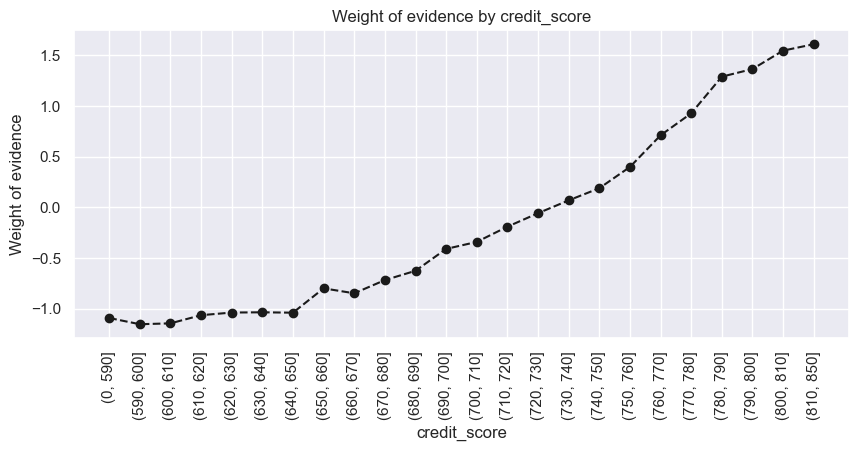

In [57]:
plot_by_woe(credit_score_table, rotation = 90)

Τhe final categoories are formed as follows:
- **$\le 650$** (8.1% of the loans): the WoE is almost constant (from $-1.15$ to $-1.04$) and it jumps by $0.24$ in the next interval.
- **$651$–$690$** (13.3%): the WoE increases slowly (from $-0.85$ to $-0.63$) and jumps by $0.22$ in the next interval.
- **$691$–$710$** (9.4%): WoE of $-0.41$ and $-0.34$, followed by a jump of $0.15$.
- **$711$–$740$** (15.4%): the WoE goes from $-0.19$ to $0.07$.
- **$741$–$760$** (12.5%): WoE of $0.19$ and $0.40$, followed by a jump of $0.31$.
- **$761$–$780$** (15.4%): WoE of $0.71$ and $0.93$, followed by a jump of $0.36$.
- **$781$–$800$** (16.9%): WoE of $1.29$ and $1.37$.
- **$> 800$** (9.0%): WoE of $1.55$ and $1.61$.

In [58]:
bins = [0, 650, 690, 710, 740, 760, 780, 800, 850]
credit_score_fine = pd.cut(df_inputs_prepr['credit_score'], bins).to_frame('credit_score')
credit_score_table = woe_ordered(credit_score_fine, 'credit_score', df_targets_prepr)
credit_score_table

,credit_score,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,"(0.0, 650.0]",15810,2373,13437,0.080674,0.210615,0.072748,-1.063030,NaN,0.150095,NaN,0.635116
1,"(650.0, 690.0]",26016,2947,23069,0.132753,0.261560,0.124896,-0.739185,0.323845,0.113276,0.036818,0.635116
2,"(690.0, 710.0]",18351,1495,16856,0.093640,0.132688,0.091259,-0.374307,0.364878,0.081467,0.031809,0.635116
3,"(710.0, 740.0]",30252,1844,28408,0.154368,0.163664,0.153801,-0.062154,0.312153,0.060955,0.020512,0.635116
4,"(740.0, 760.0]",24438,1062,23376,0.124701,0.094258,0.126558,0.294669,0.356822,0.043457,0.017498,0.635116
5,"(760.0, 780.0]",30262,791,29471,0.154419,0.070205,0.159556,0.820977,0.526308,0.026138,0.017319,0.635116
6,"(780.0, 800.0]",33090,527,32563,0.168850,0.046774,0.176296,1.326844,0.505867,0.015926,0.010212,0.635116
7,"(800.0, 850.0]",17630,222,17408,0.089961,0.019704,0.094247,1.565120,0.238276,0.012592,0.003334,0.635116
8,NaN,124,6,118,0.000633,0.000533,0.000639,0.182038,1.383083,0.048387,0.035795,0.635116


In [59]:
credit_score_fine['credit_score'] = credit_score_fine['credit_score'].fillna(credit_score_table.loc[4, 'credit_score'])
credit_score_table = woe_ordered(credit_score_fine, 'credit_score', df_targets_prepr)
credit_score_table

,credit_score,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,"(0, 650]",15810,2373,13437,0.080674,0.210615,0.072748,-1.063030,NaN,0.150095,NaN,0.635109
1,"(650, 690]",26016,2947,23069,0.132753,0.261560,0.124896,-0.739185,0.323845,0.113276,0.036818,0.635109
2,"(690, 710]",18351,1495,16856,0.093640,0.132688,0.091259,-0.374307,0.364878,0.081467,0.031809,0.635109
3,"(710, 740]",30252,1844,28408,0.154368,0.163664,0.153801,-0.062154,0.312153,0.060955,0.020512,0.635109
4,"(740, 760]",24562,1068,23494,0.125334,0.094790,0.127197,0.294070,0.356224,0.043482,0.017473,0.635109
5,"(760, 780]",30262,791,29471,0.154419,0.070205,0.159556,0.820977,0.526907,0.026138,0.017343,0.635109
6,"(780, 800]",33090,527,32563,0.168850,0.046774,0.176296,1.326844,0.505867,0.015926,0.010212,0.635109
7,"(800, 850]",17630,222,17408,0.089961,0.019704,0.094247,1.565120,0.238276,0.012592,0.003334,0.635109


**Remark.** After merging, $\text{IV} \approx 0.635$, so `credit_score` is the strongest predictor so far. The WoE increases monotonically with the score, from $-1.06$ for scores of at most 650 to $1.57$ for scores above 800, and consecutive categories differ clearly (by at least $0.24$). The IV is above $0.5$, which the rule of thumb flags as suspiciously strong, but there is no leakage: the score is known when the loan is originated and it is a standard measure of the credit quality of the borrower. The reference category is $\le 650$, the one with the lowest WoE.

In [60]:
# Create the dummies
df_inputs_prepr['credit_score:<=650'] = np.where(df_inputs_prepr['credit_score'] <= 650, 1, 0)
df_inputs_prepr['credit_score:651-690'] = np.where((df_inputs_prepr['credit_score'] > 650) & (df_inputs_prepr['credit_score'] <= 690), 1, 0)
df_inputs_prepr['credit_score:691-710'] = np.where((df_inputs_prepr['credit_score'] > 690) & (df_inputs_prepr['credit_score'] <= 710), 1, 0)
df_inputs_prepr['credit_score:711-740'] = np.where((df_inputs_prepr['credit_score'] > 710) & (df_inputs_prepr['credit_score'] <= 740), 1, 0)
df_inputs_prepr['credit_score:741-760'] = np.where(((df_inputs_prepr['credit_score'] > 740) & (df_inputs_prepr['credit_score'] <= 760)) | (df_inputs_prepr['credit_score'].isnull()), 1, 0)
df_inputs_prepr['credit_score:761-780'] = np.where((df_inputs_prepr['credit_score'] > 760) & (df_inputs_prepr['credit_score'] <= 780), 1, 0)
df_inputs_prepr['credit_score:781-800'] = np.where((df_inputs_prepr['credit_score'] > 780) & (df_inputs_prepr['credit_score'] <= 800), 1, 0)
df_inputs_prepr['credit_score:>800'] = np.where(df_inputs_prepr['credit_score'] > 800, 1, 0)

In [61]:
dummy_cols = [col for col in df_inputs_prepr.columns if col.startswith('credit_score:')]
df_inputs_prepr[dummy_cols].sum(axis = 1).value_counts()
# Expected output: 1 for all 195973 loans

1    195973
Name: count, dtype: int64

In [62]:
ref_categories['credit_score'] = 'credit_score:<=650'

#### 2. `mi_pct`

In [63]:
mi_pct_fine = pd.cut(df_inputs_prepr['mi_pct'], 50).to_frame('mi_pct')
mi_pct_table = woe_ordered(mi_pct_fine, 'mi_pct', df_targets_prepr)
mi_pct_table

C:\Users\keram\anaconda3\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


,mi_pct,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,"(-0.05, 1.0]",169202,7888,161314,0.863394,0.700098,0.873355,0.221123,NaN,0.046619,NaN,inf
1,"(1.0, 2.0]",1,0,1,0.000005,0.000000,0.000005,inf,inf,0.000000,0.046619,inf
2,"(5.0, 6.0]",451,15,436,0.002301,0.001331,0.002361,0.572705,inf,0.033259,0.033259,inf
3,"(7.0, 8.0]",2,0,2,0.000010,0.000000,0.000011,inf,inf,0.000000,0.033259,inf
4,"(8.0, 9.0]",16,2,14,0.000082,0.000178,0.000076,-0.850977,inf,0.125000,0.125000,inf
5,"(10.0, 11.0]",3,0,3,0.000015,0.000000,0.000016,inf,inf,0.000000,0.125000,inf
6,"(11.0, 12.0]",4116,454,3662,0.021003,0.040295,0.019826,-0.709220,inf,0.110301,0.110301,inf
7,"(12.0, 13.0]",30,6,24,0.000153,0.000533,0.000130,-1.410593,0.701373,0.200000,0.089699,inf
8,"(13.0, 14.0]",48,5,43,0.000245,0.000444,0.000233,-0.645125,0.765468,0.104167,0.095833,inf
9,"(14.0, 15.0]",3,0,3,0.000015,0.000000,0.000016,inf,inf,0.000000,0.104167,inf


The values of `mi_pct` are concentrated at a few levels (0, 6, 12, 17, 25, 30, 35) and 86% of the loans have `mi_pct` $\le 1$. We merge consecutive intervals with a similar WoE into 3 categories:

- **$\le 6$** (86.6% of the loans): loans without mortgage insurance, together with the 451 loans with $\text{mi\_pct} = 6$, which have a similar default rate and are too few to change the WoE of the category.
- **$7$–$27$** (8.7%): default rate of 11.5%, WoE of $-0.75$.
- **$\ge 28$** (4.7%): the highest default rate (15.2%) and the lowest WoE ($-1.08$). It contains less than 5% of the loans, but 1,411 defaults, enough for a reliable default rate.

In [64]:
bins = [-1, 6, 27, 100]
mi_pct_fine = pd.cut(df_inputs_prepr['mi_pct'], bins).to_frame('mi_pct')
mi_pct_table = woe_ordered(mi_pct_fine, 'mi_pct', df_targets_prepr)
mi_pct_table

,mi_pct,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,"(-1.0, 6.0]",169654,7903,161751,0.865701,0.701429,0.875721,0.221928,NaN,0.046583,NaN,inf
1,"(6.0, 27.0]",17055,1953,15102,0.087027,0.173338,0.081762,-0.751427,0.973355,0.114512,0.067929,inf
2,"(27.0, 100.0]",9262,1411,7851,0.047262,0.125233,0.042505,-1.080545,0.329118,0.152343,0.037831,inf
3,NaN,2,0,2,0.000010,0.000000,0.000011,inf,inf,0.000000,0.152343,inf


The 2 loans with a missing `mi_pct` are too few to form a category and are merged with the largest one, $\le 6$, because this changes the category the least.

In [65]:
mi_pct_fine['mi_pct'] = mi_pct_fine['mi_pct'].fillna(mi_pct_table.loc[0, 'mi_pct'])
mi_pct_table = woe_ordered(mi_pct_fine, 'mi_pct', df_targets_prepr)
mi_pct_table

,mi_pct,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,"(-1, 6]",169656,7903,161753,0.865711,0.701429,0.875732,0.221941,NaN,0.046582,NaN,0.196888
1,"(6, 27]",17055,1953,15102,0.087027,0.173338,0.081762,-0.751427,0.973368,0.114512,0.067929,0.196888
2,"(27, 100]",9262,1411,7851,0.047262,0.125233,0.042505,-1.080545,0.329118,0.152343,0.037831,0.196888


**Remark.** After merging, $\text{IV} \approx 0.197 > 0.02$, so `mi_pct` is kept as a medium predictor. The WoE decreases monotonically from $0.22$ (loans with $\text{mi\_pct} \le 6$) to $-1.08$ ($\text{mi\_pct} \ge 28$). The reference category is $\ge 28$, the one with the lowest WoE. Although it contains 4.7% of the loans, it has 1,411 defaults, so it is large enough.

In [66]:
# Create the dummies
df_inputs_prepr['mi_pct:<=6'] = np.where((df_inputs_prepr['mi_pct'] <= 6) | (df_inputs_prepr['mi_pct'].isnull()), 1, 0)
df_inputs_prepr['mi_pct:7-27'] = np.where((df_inputs_prepr['mi_pct'] > 6) & (df_inputs_prepr['mi_pct'] <= 27), 1, 0)
df_inputs_prepr['mi_pct:>27'] = np.where(df_inputs_prepr['mi_pct'] > 27, 1, 0)

dummy_cols = [col for col in df_inputs_prepr.columns if col.startswith('mi_pct:')]
df_inputs_prepr[dummy_cols].sum(axis = 1).value_counts()
# Expected output: 1 for all 195973 loans

1    195973
Name: count, dtype: int64

In [67]:
ref_categories['mi_pct'] = 'mi_pct:>27'

#### 3. `cltv`

In [68]:
cltv_fine = pd.cut(df_inputs_prepr['cltv'], 50).to_frame('cltv')
cltv_table = woe_ordered(cltv_fine, 'cltv', df_targets_prepr)
cltv_table

C:\Users\keram\anaconda3\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


,cltv,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,"(5.813, 9.74]",103,1,102,0.000526,0.000089,0.000552,1.828086,NaN,0.009709,NaN,inf
1,"(9.74, 13.48]",317,1,316,0.001618,0.000089,0.001711,2.958855,1.130769,0.003155,0.006554,inf
2,"(13.48, 17.22]",720,1,719,0.003674,0.000089,0.003893,3.780974,0.822119,0.001389,0.001766,inf
3,"(17.22, 20.96]",846,1,845,0.004317,0.000089,0.004575,3.942449,0.161475,0.001182,0.000207,inf
4,"(20.96, 24.7]",1478,7,1471,0.007542,0.000621,0.007964,2.550900,1.391549,0.004736,0.003554,inf
5,"(24.7, 28.44]",2186,9,2177,0.011155,0.000799,0.011786,2.691591,0.140691,0.004117,0.000619,inf
6,"(28.44, 32.18]",2753,14,2739,0.014048,0.001243,0.014829,2.479404,0.212188,0.005085,0.000968,inf
7,"(32.18, 35.92]",2495,19,2476,0.012731,0.001686,0.013405,2.073073,0.406330,0.007615,0.002530,inf
8,"(35.92, 39.66]",4003,34,3969,0.020426,0.003018,0.021488,1.963022,0.110052,0.008494,0.000878,inf
9,"(39.66, 43.4]",4713,50,4663,0.024049,0.004438,0.025246,1.738504,0.224518,0.010609,0.002115,inf


In [69]:
bins = [0, 25] + list(range(30, 106, 5)) + [250]
bins

[0, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70, 75, 80, 85, 90, 95, 100, 105, 250]

In [70]:
cltv_fine = pd.cut(df_inputs_prepr['cltv'], bins).to_frame('cltv')
cltv_table = woe_ordered(cltv_fine, 'cltv', df_targets_prepr)
cltv_table

,cltv,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,"(0.0, 25.0]",3956,15,3941,0.020186,0.001331,0.021337,2.774252,NaN,0.003792,NaN,inf
1,"(25.0, 30.0]",3030,10,3020,0.015461,0.000888,0.016350,2.913540,0.139287,0.003300,0.000491,inf
2,"(30.0, 35.0]",3912,28,3884,0.019962,0.002485,0.021028,2.135529,0.778011,0.007157,0.003857,inf
3,"(35.0, 40.0]",5257,43,5214,0.026825,0.003816,0.028229,2.001015,0.134514,0.008180,0.001022,inf
4,"(40.0, 45.0]",6144,76,6068,0.031351,0.006745,0.032852,1.583164,0.417851,0.012370,0.004190,inf
5,"(45.0, 50.0]",7841,105,7736,0.040011,0.009319,0.041883,1.502792,0.080371,0.013391,0.001021,inf
6,"(50.0, 55.0]",8801,174,8627,0.044909,0.015443,0.046707,1.106710,0.396083,0.019770,0.006379,inf
7,"(55.0, 60.0]",11242,260,10982,0.057365,0.023076,0.059457,0.946444,0.160266,0.023128,0.003357,inf
8,"(60.0, 65.0]",11660,419,11241,0.059498,0.037188,0.060859,0.492565,0.453879,0.035935,0.012807,inf
9,"(65.0, 70.0]",17268,916,16352,0.088114,0.081299,0.088530,0.085202,0.407363,0.053046,0.017111,inf


The 14 loans with a missing `cltv` have no defaults, so they give no information about the risk. They are too few to form a category and are merged with the largest interval, which changes it the least.

In [71]:
largest = cltv_table.loc[cltv_table['n_obs'].idxmax(), 'cltv']
largest

Interval(75, 80, closed='right')

In [72]:
cltv_fine['cltv'] = cltv_fine['cltv'].fillna(largest)
cltv_table = woe_ordered(cltv_fine, 'cltv', df_targets_prepr)
cltv_table

,cltv,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,"(0, 25]",3956,15,3941,0.020186,0.001331,0.021337,2.774252,NaN,0.003792,NaN,0.51662
1,"(25, 30]",3030,10,3020,0.015461,0.000888,0.016350,2.913540,0.139287,0.003300,0.000491,0.51662
2,"(30, 35]",3912,28,3884,0.019962,0.002485,0.021028,2.135529,0.778011,0.007157,0.003857,0.51662
3,"(35, 40]",5257,43,5214,0.026825,0.003816,0.028229,2.001015,0.134514,0.008180,0.001022,0.51662
4,"(40, 45]",6144,76,6068,0.031351,0.006745,0.032852,1.583164,0.417851,0.012370,0.004190,0.51662
5,"(45, 50]",7841,105,7736,0.040011,0.009319,0.041883,1.502792,0.080371,0.013391,0.001021,0.51662
6,"(50, 55]",8801,174,8627,0.044909,0.015443,0.046707,1.106710,0.396083,0.019770,0.006379,0.51662
7,"(55, 60]",11242,260,10982,0.057365,0.023076,0.059457,0.946444,0.160266,0.023128,0.003357,0.51662
8,"(60, 65]",11660,419,11241,0.059498,0.037188,0.060859,0.492565,0.453879,0.035935,0.012807,0.51662
9,"(65, 70]",17268,916,16352,0.088114,0.081299,0.088530,0.085202,0.407363,0.053046,0.017111,0.51662


C:\Users\keram\AppData\Local\Temp\ipykernel_9292\3094246576.py:2: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  x = table.iloc[:, 0].astype(object).fillna('missing').astype(str)


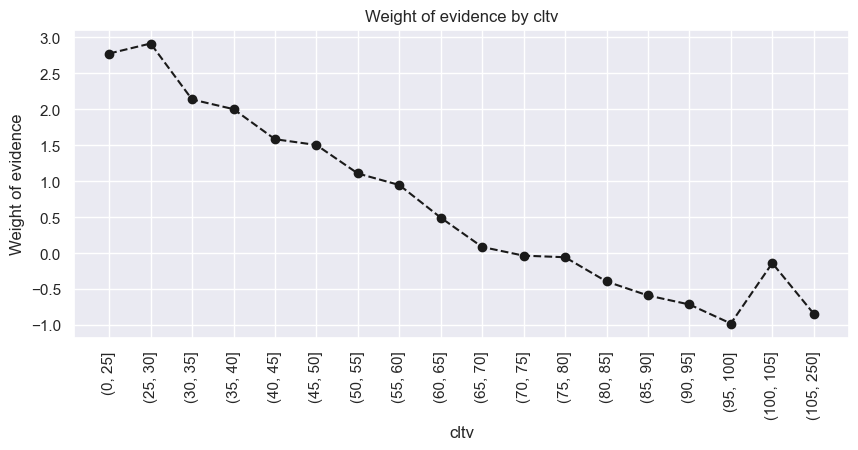

In [73]:
plot_by_woe(cltv_table, rotation = 90)

Final categories are formed as follows:

- **$\le 40$** (8.2% of the loans): default rate of 0.6%, WoE of $2.32$. The intervals below 30 contain few loans and only 25 defaults, so they are merged with the next ones.
- **$41$–$50$** (7.1%): WoE of $1.54$.
- **$51$–$60$** (10.2%): WoE of $1.01$.
- **$61$–$65$** (5.9%): WoE of $0.49$.
- **$66$–$80$** (44.5%): WoE of $-0.03$. It contains the large group of loans with a cltv of $80$.
- **$> 80$** (24.0%): the highest default rate (10.7%) and the lowest WoE ($-0.67$).

In [74]:
bins = [0, 40, 50, 60, 65, 80, 250]
cltv_fine = pd.cut(df_inputs_prepr['cltv'], bins).to_frame('cltv')
cltv_table = woe_ordered(cltv_fine, 'cltv', df_targets_prepr)
cltv_table

,cltv,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,"(0.0, 40.0]",16155,96,16059,0.082435,0.008520,0.086944,2.322789,NaN,0.005942,NaN,inf
1,"(40.0, 50.0]",13985,181,13804,0.071362,0.016065,0.074735,1.537329,0.785460,0.012942,0.007000,inf
2,"(50.0, 60.0]",20043,434,19609,0.102274,0.038520,0.106163,1.013812,0.523517,0.021653,0.008711,inf
3,"(60.0, 65.0]",11660,419,11241,0.059498,0.037188,0.060859,0.492565,0.521247,0.035935,0.014281,inf
4,"(65.0, 80.0]",87179,5137,82042,0.444852,0.455933,0.444176,-0.026125,0.518690,0.058925,0.022990,inf
5,"(80.0, 250.0]",46937,5000,41937,0.239507,0.443774,0.227047,-0.670157,0.644031,0.106526,0.047601,inf
6,NaN,14,0,14,0.000071,0.000000,0.000076,inf,inf,0.000000,0.106526,inf


Missing values are merged with the largest category

In [75]:
largest = cltv_table.loc[cltv_table['n_obs'].idxmax(), 'cltv']
largest
# Expected output: Interval(65, 80, closed='right')

Interval(65, 80, closed='right')

In [76]:
cltv_fine['cltv'] = cltv_fine['cltv'].fillna(largest)
cltv_table = woe_ordered(cltv_fine, 'cltv', df_targets_prepr)
cltv_table

,cltv,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,"(0, 40]",16155,96,16059,0.082435,0.008520,0.086944,2.322789,NaN,0.005942,NaN,0.498137
1,"(40, 50]",13985,181,13804,0.071362,0.016065,0.074735,1.537329,0.785460,0.012942,0.007000,0.498137
2,"(50, 60]",20043,434,19609,0.102274,0.038520,0.106163,1.013812,0.523517,0.021653,0.008711,0.498137
3,"(60, 65]",11660,419,11241,0.059498,0.037188,0.060859,0.492565,0.521247,0.035935,0.014281,0.498137
4,"(65, 80]",87193,5137,82056,0.444924,0.455933,0.444252,-0.025955,0.518519,0.058915,0.022980,0.498137
5,"(80, 250]",46937,5000,41937,0.239507,0.443774,0.227047,-0.670157,0.644202,0.106526,0.047610,0.498137


**Remark.** After merging, $\text{IV} \approx 0.498 > 0.02$, so `cltv` is kept as a strong predictor. The WoE decreases monotonically from $2.32$ (cltv of at most 40) to $-0.67$ (cltv above 80), and consecutive categories differ clearly (by at least $0.52$). The reference category is $> 80$, the one with the lowest WoE.

In [77]:
# Create the dummies
df_inputs_prepr['cltv:<=40'] = np.where(df_inputs_prepr['cltv'] <= 40, 1, 0)
df_inputs_prepr['cltv:41-50'] = np.where((df_inputs_prepr['cltv'] > 40) & (df_inputs_prepr['cltv'] <= 50), 1, 0)
df_inputs_prepr['cltv:51-60'] = np.where((df_inputs_prepr['cltv'] > 50) & (df_inputs_prepr['cltv'] <= 60), 1, 0)
df_inputs_prepr['cltv:61-65'] = np.where((df_inputs_prepr['cltv'] > 60) & (df_inputs_prepr['cltv'] <= 65), 1, 0)
df_inputs_prepr['cltv:66-80'] = np.where(((df_inputs_prepr['cltv'] > 65) & (df_inputs_prepr['cltv'] <= 80)) | (df_inputs_prepr['cltv'].isnull()), 1, 0)
df_inputs_prepr['cltv:>80'] = np.where(df_inputs_prepr['cltv'] > 80, 1, 0)

dummy_cols = [col for col in df_inputs_prepr.columns if col.startswith('cltv:')]
df_inputs_prepr[dummy_cols].sum(axis = 1).value_counts()
# Expected output: 1 for all 195973 loans

1    195973
Name: count, dtype: int64

In [78]:
ref_categories['cltv'] = 'cltv:>80'

#### 4. `dti`

In [79]:
dti_fine = pd.cut(df_inputs_prepr['dti'], 50).to_frame('dti')
dti_table = woe_ordered(dti_fine, 'dti', df_targets_prepr)
dti_table

,dti,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,"(0.936, 2.28]",68,1,67,0.000347,0.000089,0.000363,1.407805,NaN,0.014706,NaN,0.199781
1,"(2.28, 3.56]",73,4,69,0.000373,0.000355,0.000374,0.050925,1.356880,0.054795,0.040089,0.199781
2,"(3.56, 4.84]",122,2,120,0.000623,0.000178,0.000650,1.297457,1.246532,0.016393,0.038401,0.199781
3,"(4.84, 6.12]",444,9,435,0.002266,0.000799,0.002355,1.081234,0.216223,0.020270,0.003877,0.199781
4,"(6.12, 7.4]",364,9,355,0.001857,0.000799,0.001922,0.878006,0.203228,0.024725,0.004455,0.199781
5,"(7.4, 8.68]",449,12,437,0.002291,0.001065,0.002366,0.798139,0.079867,0.026726,0.002001,0.199781
6,"(8.68, 9.96]",683,13,670,0.003485,0.001154,0.003627,1.145441,0.347302,0.019034,0.007692,0.199781
7,"(9.96, 11.24]",1727,42,1685,0.008812,0.003728,0.009123,0.894964,0.250477,0.024320,0.005286,0.199781
8,"(11.24, 12.52]",1174,21,1153,0.005991,0.001864,0.006242,1.208713,0.313749,0.017888,0.006432,0.199781
9,"(12.52, 13.8]",1419,41,1378,0.007241,0.003639,0.007461,0.717929,0.490784,0.028894,0.011006,0.199781


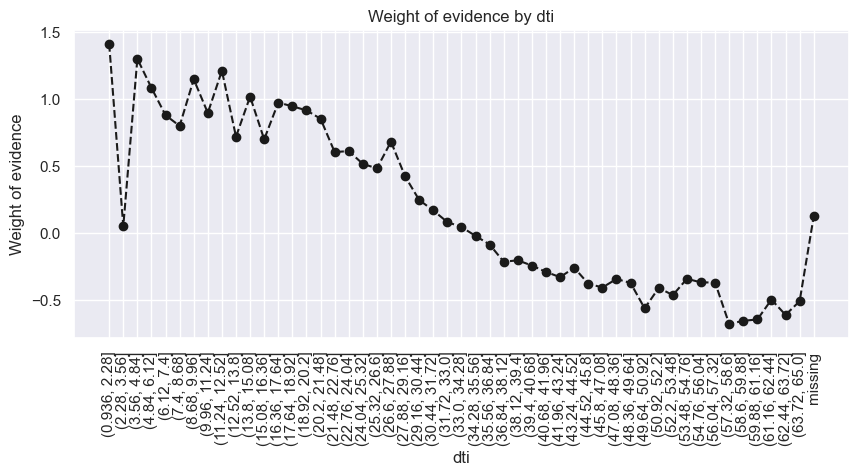

In [80]:
plot_by_woe(dti_table, rotation = 90)

**Coarse classing: first step.** The first 16 fine intervals (dti ≤ 21.48) contain 12,261 + 18,896 − ... loans in total with very noisy individual WoE values (from 0.70 to 1.41, no trend), mostly because of intervals with only a few dozen loans and 1–4 defaults. Their WoE values fluctuate around 0.9 without a trend, and the first drop appears only in the interval (21.48, 22.76]. We therefore merge the intervals up to 21.48 into one category and plot the table again, to decide the remaining boundaries.

In [81]:
bins = [0, 21.48, 22.76, 24.04, 25.32, 26.6, 27.88, 29.16, 30.44, 31.72, 33.0, 34.28, 35.56, 36.84, 38.12, 39.4, 40.68, 41.96, 43.24, 44.52, 45.8, 47.08, 48.36, 49.64, 50.92, 52.2, 53.48, 54.76, 56.04, 57.32, 58.6, 59.88, 61.16, 62.44, 63.72, 65.0]
dti_fine = pd.cut(df_inputs_prepr['dti'], bins).to_frame('dti')
dti_table = woe_ordered(dti_fine, 'dti', df_targets_prepr)
dti_table

,dti,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,"(0.0, 21.48]",27377,656,26721,0.139698,0.058223,0.144668,0.910157,NaN,0.023962,NaN,0.198
1,"(21.48, 22.76]",3780,122,3658,0.019288,0.010828,0.019804,0.603764,0.306393,0.032275,0.008313,0.198
2,"(22.76, 24.04]",8423,270,8153,0.042980,0.023964,0.044140,0.610832,0.007068,0.032055,0.000220,0.198
3,"(24.04, 25.32]",4525,159,4366,0.023090,0.014112,0.023638,0.515811,0.095021,0.035138,0.003083,0.198
4,"(25.32, 26.6]",4767,173,4594,0.024325,0.015355,0.024872,0.482328,0.033484,0.036291,0.001153,0.198
5,"(26.6, 27.88]",4742,142,4600,0.024197,0.012603,0.024904,0.681097,0.198770,0.029945,0.006346,0.198
6,"(27.88, 29.16]",10146,390,9756,0.051772,0.034614,0.052819,0.422604,0.258494,0.038439,0.008494,0.198
7,"(29.16, 30.44]",5300,241,5059,0.027045,0.021390,0.027389,0.247240,0.175364,0.045472,0.007033,0.198
8,"(30.44, 31.72]",5388,264,5124,0.027494,0.023431,0.027741,0.168854,0.078386,0.048998,0.003526,0.198
9,"(31.72, 33.0]",10929,581,10348,0.055768,0.051567,0.056024,0.082911,0.085944,0.053161,0.004164,0.198


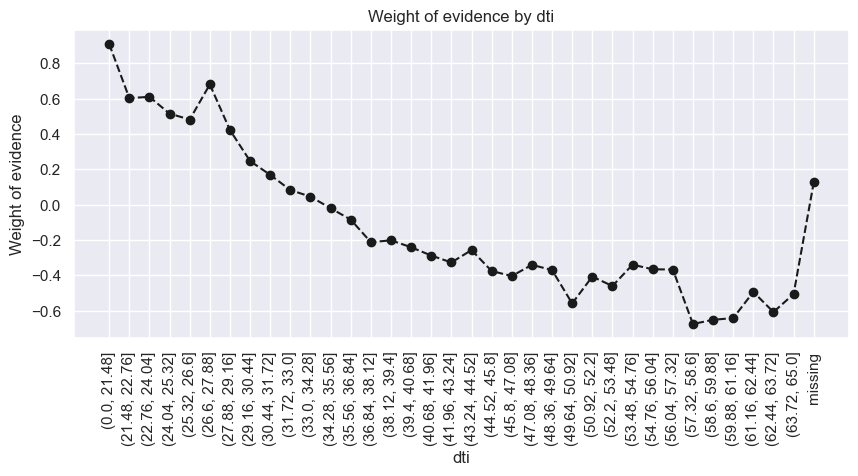

In [82]:
plot_by_woe(dti_table, rotation = 90)

In [83]:
bins = [0, 21.48, 29.16, 36.84, 44.52, 65]
dti_fine = pd.cut(df_inputs_prepr['dti'], bins).to_frame('dti')
dti_table = woe_ordered(dti_fine, 'dti', df_targets_prepr)
dti_table

,dti,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,"(0.0, 21.48]",27377,656,26721,0.139698,0.058223,0.144668,0.910157,NaN,0.023962,NaN,0.19143
1,"(21.48, 29.16]",36383,1256,35127,0.185653,0.111476,0.190178,0.534151,0.376006,0.034522,0.010560,0.19143
2,"(29.16, 36.84]",38026,2048,35978,0.194037,0.181770,0.194785,0.069157,0.464994,0.053858,0.019336,0.19143
3,"(36.84, 44.52]",41313,3021,38292,0.210810,0.268128,0.207313,-0.257234,0.326391,0.073125,0.019267,0.19143
4,"(44.52, 65.0]",44901,3879,41022,0.229118,0.344280,0.222093,-0.438356,0.181122,0.086390,0.013265,0.19143
5,NaN,7973,407,7566,0.040684,0.036123,0.040962,0.125719,0.564076,0.051047,0.035343,0.19143


**Missing values.** The 7,973 loans with missing `dti` (4.1% of the training set) have a default rate of 5.10% (WoE 0.126), which does not justify a separate category. Following the rule of Section 2.4.1, we merge them with the category whose default rate and WoE are closest, namely (29.16, 36.84] (default rate 5.39%, WoE 0.069).

In [84]:
dti_fine = pd.cut(df_inputs_prepr['dti'].fillna(33), bins).to_frame('dti')
dti_table = woe_ordered(dti_fine, 'dti', df_targets_prepr)
dti_table

,dti,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,"(0.0, 21.48]",27377,656,26721,0.139698,0.058223,0.144668,0.910157,NaN,0.023962,NaN,0.191328
1,"(21.48, 29.16]",36383,1256,35127,0.185653,0.111476,0.190178,0.534151,0.376006,0.034522,0.010560,0.191328
2,"(29.16, 36.84]",45999,2455,43544,0.234721,0.217893,0.235748,0.078758,0.455393,0.053371,0.018849,0.191328
3,"(36.84, 44.52]",41313,3021,38292,0.210810,0.268128,0.207313,-0.257234,0.335992,0.073125,0.019754,0.191328
4,"(44.52, 65.0]",44901,3879,41022,0.229118,0.344280,0.222093,-0.438356,0.181122,0.086390,0.013265,0.191328


**Result.** The IV of `dti` with five categories is 0.191 (medium predictive power), practically unchanged from the value before merging the missing values (0.191). The WoE decreases monotonically with `dti`, from 0.91 for (0, 21.48] to -0.44 for (44.52, 65]: the higher the debt-to-income ratio, the higher the default rate, as expected. The variable is kept. The reference category will be the one with the lowest WoE, (44.52, 65].

In [85]:
df_inputs_prepr['dti:<=21.48'] = np.where(df_inputs_prepr['dti'] <= 21.48, 1, 0)
df_inputs_prepr['dti:21.48-29.16'] = np.where((df_inputs_prepr['dti'] > 21.48) & (df_inputs_prepr['dti'] <= 29.16), 1, 0)
df_inputs_prepr['dti:29.16-36.84'] = np.where(((df_inputs_prepr['dti'] > 29.16) & (df_inputs_prepr['dti'] <= 36.84)) | (df_inputs_prepr['dti'].isnull()), 1, 0)
df_inputs_prepr['dti:36.84-44.52'] = np.where((df_inputs_prepr['dti'] > 36.84) & (df_inputs_prepr['dti'] <= 44.52), 1, 0)
df_inputs_prepr['dti:>44.52'] = np.where(df_inputs_prepr['dti'] > 44.52, 1, 0)

In [86]:
dti_cols = ['dti:<=21.48', 'dti:21.48-29.16', 'dti:29.16-36.84', 'dti:36.84-44.52', 'dti:>44.52']
df_inputs_prepr[dti_cols].sum(axis = 1).value_counts()

1    195973
Name: count, dtype: int64

In [87]:
ref_categories['dti'] = 'dti:>44.52'

#### 5. `orig_upb`

In [88]:
orig_upb_fine = pd.cut(df_inputs_prepr['orig_upb'], 50).to_frame('orig_upb')
orig_upb_table = woe_ordered(orig_upb_fine, 'orig_upb', df_targets_prepr)
orig_upb_table

,orig_upb,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,"(7914.0, 30720.0]",869,51,818,0.004434,0.004526,0.004429,-0.021851,NaN,0.058688,NaN,inf
1,"(30720.0, 52440.0]",5601,300,5301,0.028580,0.026626,0.028700,0.074981,0.096832,0.053562,0.005126,inf
2,"(52440.0, 74160.0]",11978,702,11276,0.061121,0.062306,0.061048,-0.020389,0.095370,0.058607,0.005046,inf
3,"(74160.0, 95880.0]",16256,889,15367,0.082950,0.078903,0.083197,0.052993,0.073382,0.054688,0.003920,inf
4,"(95880.0, 117600.0]",20414,1058,19356,0.104167,0.093903,0.104794,0.109735,0.056742,0.051827,0.002860,inf
5,"(117600.0, 139320.0]",19623,1122,18501,0.100131,0.099583,0.100165,0.005825,0.103910,0.057178,0.005351,inf
6,"(139320.0, 161040.0]",19753,1113,18640,0.100794,0.098784,0.100917,0.021363,0.015539,0.056346,0.000832,inf
7,"(161040.0, 182760.0]",15065,947,14118,0.076873,0.084051,0.076435,-0.094981,0.116344,0.062861,0.006515,inf
8,"(182760.0, 204480.0]",14869,923,13946,0.075873,0.081921,0.075504,-0.081568,0.013412,0.062075,0.000785,inf
9,"(204480.0, 226200.0]",11970,766,11204,0.061080,0.067986,0.060659,-0.114043,0.032475,0.063993,0.001918,inf


**Coarse classing: first step.** The fine classing of `orig_upb` shows two kinds of intervals that cannot stand as separate categories:

- The first three intervals (up to 74,160) contain 869, 5,601 and 11,978 loans. The first two are below 5% of the loans each (0.4% and 2.9%) and all three have WoE values close to zero (-0.02, 0.07, -0.02), so we merge them into one category.
- The intervals above 399,960 are very small (from 2 to 166 loans each) and many of them have no defaults, so their WoE is infinite or based on very few defaults. Together with the interval (399,960, 421,680] (8,482 loans), which has the same WoE (0.42) as the next interval and is separated from the previous one by the largest jump of the variable (the default rate drops from 5.84% to 3.87%), they form one category with more than 5% of the loans.

We plot the table again with these merges to decide the remaining boundaries.

In [89]:
bins = [0, 74160, 95880, 117600, 139320, 161040, 182760, 204480, 226200, 247920, 269640, 291360, 313080, 334800, 356520, 378240, 399960, 1100000]
orig_upb_fine = pd.cut(df_inputs_prepr['orig_upb'], bins).to_frame('orig_upb')
orig_upb_table = woe_ordered(orig_upb_fine, 'orig_upb', df_targets_prepr)
orig_upb_table

,orig_upb,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,"(0, 74160]",18448,1053,17395,0.094135,0.093459,0.094177,0.007652,NaN,0.057079,NaN,0.016817
1,"(74160, 95880]",16256,889,15367,0.082950,0.078903,0.083197,0.052993,0.045341,0.054688,0.002392,0.016817
2,"(95880, 117600]",20414,1058,19356,0.104167,0.093903,0.104794,0.109735,0.056742,0.051827,0.002860,0.016817
3,"(117600, 139320]",19623,1122,18501,0.100131,0.099583,0.100165,0.005825,0.103910,0.057178,0.005351,0.016817
4,"(139320, 161040]",19753,1113,18640,0.100794,0.098784,0.100917,0.021363,0.015539,0.056346,0.000832,0.016817
5,"(161040, 182760]",15065,947,14118,0.076873,0.084051,0.076435,-0.094981,0.116344,0.062861,0.006515,0.016817
6,"(182760, 204480]",14869,923,13946,0.075873,0.081921,0.075504,-0.081568,0.013412,0.062075,0.000785,0.016817
7,"(204480, 226200]",11970,766,11204,0.061080,0.067986,0.060659,-0.114043,0.032475,0.063993,0.001918,0.016817
8,"(226200, 247920]",9368,609,8759,0.047803,0.054052,0.047421,-0.130869,0.016825,0.065009,0.001015,0.016817
9,"(247920, 269640]",9048,543,8505,0.046170,0.048194,0.046046,-0.045587,0.085281,0.060013,0.004995,0.016817


**Remark.** After merging the first three intervals and the intervals above 399,960, the IV of `orig_upb` with 17 categories is 0.017, below the 0.02 threshold. We therefore do not use `orig_upb` in the model and do not create dummy variables for it.

#### 6. `ltv`

In [90]:
ltv_fine = pd.cut(df_inputs_prepr['ltv'], 50).to_frame('ltv')
ltv_table = woe_ordered(ltv_fine, 'ltv', df_targets_prepr)
ltv_table

,ltv,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,"(5.881, 8.38]",77,1,76,0.000393,0.000089,0.000411,1.533846,NaN,0.012987,NaN,inf
1,"(8.38, 10.76]",102,0,102,0.000520,0.000000,0.000552,inf,inf,0.000000,0.012987,inf
2,"(10.76, 13.14]",277,1,276,0.001413,0.000089,0.001494,2.823514,inf,0.003610,0.003610,inf
3,"(13.14, 15.52]",344,0,344,0.001755,0.000000,0.001862,inf,inf,0.000000,0.003610,inf
4,"(15.52, 17.9]",448,1,447,0.002286,0.000089,0.002420,3.305671,inf,0.002232,0.002232,inf
5,"(17.9, 20.28]",921,1,920,0.004700,0.000089,0.004981,4.027486,0.721815,0.001086,0.001146,inf
6,"(20.28, 22.66]",700,2,698,0.003572,0.000178,0.003779,3.058185,0.969302,0.002857,0.001771,inf
7,"(22.66, 25.04]",1451,9,1442,0.007404,0.000799,0.007807,2.279674,0.778510,0.006203,0.003345,inf
8,"(25.04, 27.42]",1163,4,1159,0.005934,0.000355,0.006275,2.872131,0.592457,0.003439,0.002763,inf
9,"(27.42, 29.8]",1341,4,1337,0.006843,0.000355,0.007239,3.015002,0.142871,0.002983,0.000457,inf


**Coarse classing: first step.** We merge the first ten intervals (`ltv` ≤ 29.8), which contain between 77 and 1,451 loans each and at most 9 defaults, and the intervals above 98.82, which are very small (3 to 137 loans). We then compute the table and plot it again to decide the remaining boundaries.

In [91]:
bins = [0, 29.8, 32.18, 34.56, 36.94, 39.32, 41.7, 44.08, 46.46, 48.84, 51.22, 53.6, 55.98, 58.36, 60.74, 63.12, 65.5, 67.88, 70.26, 72.64, 75.02, 77.4, 79.78, 82.16, 84.54, 86.92, 89.3, 91.68, 94.06, 96.44, 98.82, 126]
ltv_fine = pd.cut(df_inputs_prepr['ltv'], bins).to_frame('ltv')
ltv_table = woe_ordered(ltv_fine, 'ltv', df_targets_prepr)
ltv_table

,ltv,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,"(0.0, 29.8]",6824,23,6801,0.034821,0.002041,0.036821,2.892443,NaN,0.003370,NaN,inf
1,"(29.8, 32.18]",2269,12,2257,0.011578,0.001065,0.012219,2.439998,0.452446,0.005289,0.001918,inf
2,"(32.18, 34.56]",1750,13,1737,0.008930,0.001154,0.009404,2.098078,0.341920,0.007429,0.002140,inf
3,"(34.56, 36.94]",1952,12,1940,0.009961,0.001065,0.010503,2.288649,0.190571,0.006148,0.001281,inf
4,"(36.94, 39.32]",3286,34,3252,0.016768,0.003018,0.017606,1.763778,0.524872,0.010347,0.004199,inf
5,"(39.32, 41.7]",2375,21,2354,0.012119,0.001864,0.012745,1.922462,0.158684,0.008842,0.001505,inf
6,"(41.7, 44.08]",4123,58,4065,0.021039,0.005148,0.022008,1.452839,0.469623,0.014067,0.005225,inf
7,"(44.08, 46.46]",2847,33,2814,0.014528,0.002929,0.015235,1.648967,0.196129,0.011591,0.002476,inf
8,"(46.46, 48.84]",3136,35,3101,0.016002,0.003106,0.016789,1.687245,0.038277,0.011161,0.000430,inf
9,"(48.84, 51.22]",5336,88,5248,0.027228,0.007810,0.028413,1.291378,0.395866,0.016492,0.005331,inf


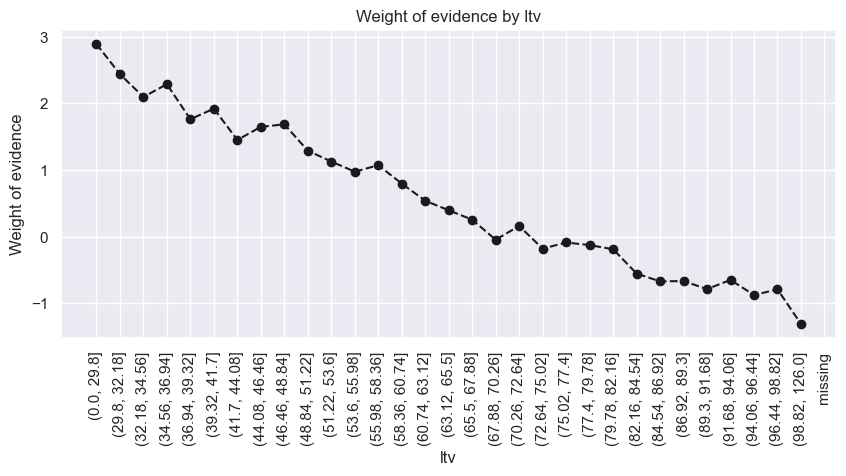

In [92]:
plot_by_woe(ltv_table, rotation = 90)

**Coarse classing.** We group the fine intervals of `ltv` into seven categories with boundaries at 34.56, 39.32, 48.84, 58.36, 67.88 and 82.16. Intervals with few loans and very few defaults (`ltv` ≤ 29.8) are merged with the next one, and within each category the WoE varies little. The WoE decreases steadily as `ltv` increases.

In [93]:
bins = [0, 34.56, 39.32, 48.84, 58.36, 67.88, 82.16, 126]
ltv_fine = pd.cut(df_inputs_prepr['ltv'], bins).to_frame('ltv')
ltv_table = woe_ordered(ltv_fine, 'ltv', df_targets_prepr)
ltv_table

,ltv,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,"(0.0, 34.56]",10843,48,10795,0.055329,0.004260,0.058444,2.618750,NaN,0.004427,NaN,inf
1,"(34.56, 39.32]",5238,46,5192,0.026728,0.004083,0.028110,1.929346,0.689404,0.008782,0.004355,inf
2,"(39.32, 48.84]",12481,147,12334,0.063687,0.013047,0.066776,1.632795,0.296550,0.011778,0.002996,inf
3,"(48.84, 58.36]",19537,382,19155,0.099692,0.033904,0.103705,1.118011,0.514784,0.019553,0.007775,inf
4,"(58.36, 67.88]",22990,835,22155,0.117312,0.074110,0.119947,0.481499,0.636512,0.036320,0.016767,inf
5,"(67.88, 82.16]",96642,6337,90305,0.493139,0.562439,0.488912,-0.140100,0.621599,0.065572,0.029252,inf
6,"(82.16, 126.0]",28229,3472,24757,0.144045,0.308157,0.134035,-0.832510,0.692410,0.122994,0.057422,inf
7,NaN,13,0,13,0.000066,0.000000,0.000070,inf,inf,0.000000,0.122994,inf


**Coarse classing.** We merge intervals 1 and 2, because interval 1 has few loans and interval 2 is the closest to it in WoE. We also merge missing values with the largest category.

In [94]:
bins = [0, 34.56, 48.84, 58.36, 67.88, 82.16, 126]
ltv_fine = pd.cut(df_inputs_prepr['ltv'].fillna(75), bins).to_frame('ltv')
ltv_table = woe_ordered(ltv_fine, 'ltv', df_targets_prepr)
ltv_table

,ltv,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,"(0.0, 34.56]",10843,48,10795,0.055329,0.004260,0.058444,2.618750,NaN,0.004427,NaN,0.53035
1,"(34.56, 48.84]",17719,193,17526,0.090416,0.017130,0.094886,1.711863,0.906887,0.010892,0.006465,0.53035
2,"(48.84, 58.36]",19537,382,19155,0.099692,0.033904,0.103705,1.118011,0.593852,0.019553,0.008660,0.53035
3,"(58.36, 67.88]",22990,835,22155,0.117312,0.074110,0.119947,0.481499,0.636512,0.036320,0.016767,0.53035
4,"(67.88, 82.16]",96655,6337,90318,0.493206,0.562439,0.488982,-0.139956,0.621455,0.065563,0.029243,0.53035
5,"(82.16, 126.0]",28229,3472,24757,0.144045,0.308157,0.134035,-0.832510,0.692554,0.122994,0.057431,0.53035


**Result.** IV of `ltv` = 0.530 (strong). The WoE decreases monotonically with `ltv`. The variable is kept; the reference category is (82.16, 126].

In [95]:
df_inputs_prepr['ltv:<=34.56'] = np.where(df_inputs_prepr['ltv'] <= 34.56, 1, 0)
df_inputs_prepr['ltv:34.56-48.84'] = np.where((df_inputs_prepr['ltv'] > 34.56) & (df_inputs_prepr['ltv'] <= 48.84), 1, 0)
df_inputs_prepr['ltv:48.84-58.36'] = np.where((df_inputs_prepr['ltv'] > 48.84) & (df_inputs_prepr['ltv'] <= 58.36), 1, 0)
df_inputs_prepr['ltv:58.36-67.88'] = np.where((df_inputs_prepr['ltv'] > 58.36) & (df_inputs_prepr['ltv'] <= 67.88), 1, 0)
df_inputs_prepr['ltv:67.88-82.16'] = np.where(((df_inputs_prepr['ltv'] > 67.88) & (df_inputs_prepr['ltv'] <= 82.16)) | (df_inputs_prepr['ltv'].isnull()), 1, 0)
df_inputs_prepr['ltv:>82.16'] = np.where(df_inputs_prepr['ltv'] > 82.16, 1, 0)

In [96]:
ltv_cols = ['ltv:<=34.56', 'ltv:34.56-48.84', 'ltv:48.84-58.36', 'ltv:58.36-67.88', 'ltv:67.88-82.16', 'ltv:>82.16']
df_inputs_prepr[ltv_cols].sum(axis = 1).value_counts()

1    195973
Name: count, dtype: int64

In [97]:
ref_categories['ltv'] = 'ltv:>82.16'

#### 7. `int_rate`

In [98]:
int_rate_fine = pd.cut(df_inputs_prepr['int_rate'], 50).to_frame('int_rate')
int_rate_table = woe_ordered(int_rate_fine, 'int_rate', df_targets_prepr)
int_rate_table

,int_rate,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,"(2.618, 2.758]",3,0,3,0.000015,0.000000,0.000016,inf,NaN,0.000000,NaN,inf
1,"(3.42, 3.552]",3,0,3,0.000015,0.000000,0.000016,inf,NaN,0.000000,0.000000,inf
2,"(3.552, 3.685]",1,0,1,0.000005,0.000000,0.000005,inf,NaN,0.000000,0.000000,inf
3,"(3.685, 3.818]",3,0,3,0.000015,0.000000,0.000016,inf,NaN,0.000000,0.000000,inf
4,"(3.818, 3.95]",5,0,5,0.000026,0.000000,0.000027,inf,NaN,0.000000,0.000000,inf
5,"(3.95, 4.082]",7,0,7,0.000036,0.000000,0.000038,inf,NaN,0.000000,0.000000,inf
6,"(4.082, 4.215]",10,0,10,0.000051,0.000000,0.000054,inf,NaN,0.000000,0.000000,inf
7,"(4.215, 4.348]",1235,3,1232,0.006302,0.000266,0.006670,3.220895,inf,0.002429,0.002429,inf
8,"(4.348, 4.48]",1568,2,1566,0.008001,0.000178,0.008478,3.866245,0.645351,0.001276,0.001154,inf
9,"(4.48, 4.612]",2541,7,2534,0.012966,0.000621,0.013719,3.094757,0.771488,0.002755,0.001479,inf


**Coarse classing: first step.** We merge the intervals with `int_rate` ≤ 4.745 and those above 6.865, which contain very few loans or defaults. We then compute the table and plot it again to decide the remaining boundaries.

In [99]:
bins = [0, 4.745, 4.877, 5.01, 5.142, 5.275, 5.408, 5.54, 5.672, 5.805, 5.938, 6.07, 6.203, 6.335, 6.468, 6.6, 6.732, 6.865, 10]
int_rate_fine = pd.cut(df_inputs_prepr['int_rate'], bins).to_frame('int_rate')
int_rate_table = woe_ordered(int_rate_fine, 'int_rate', df_targets_prepr)
int_rate_table

,int_rate,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,"(0.0, 4.745]",7849,21,7828,0.040051,0.001864,0.042381,3.124053,NaN,0.002676,NaN,0.65086
1,"(4.745, 4.877]",14879,94,14785,0.075924,0.008343,0.080046,2.261186,0.862866,0.006318,0.003642,0.65086
2,"(4.877, 5.01]",5434,55,5379,0.027728,0.004882,0.029122,1.786037,0.475149,0.010121,0.003804,0.65086
3,"(5.01, 5.142]",4518,65,4453,0.023054,0.005769,0.024109,1.430059,0.355979,0.014387,0.004265,0.65086
4,"(5.142, 5.275]",6909,106,6803,0.035255,0.009408,0.036832,1.364793,0.065266,0.015342,0.000955,0.65086
5,"(5.275, 5.408]",7712,176,7536,0.039352,0.015621,0.040800,0.960076,0.404717,0.022822,0.007479,0.65086
6,"(5.408, 5.54]",9028,265,8763,0.046068,0.023520,0.047443,0.701676,0.258399,0.029353,0.006532,0.65086
7,"(5.54, 5.672]",8896,315,8581,0.045394,0.027958,0.046458,0.507846,0.193831,0.035409,0.006056,0.65086
8,"(5.672, 5.805]",12341,535,11806,0.062973,0.047484,0.063918,0.297209,0.210637,0.043351,0.007942,0.65086
9,"(5.805, 5.938]",17604,965,16639,0.089829,0.085648,0.090084,0.050489,0.246720,0.054817,0.011466,0.65086


C:\Users\keram\AppData\Local\Temp\ipykernel_9292\3094246576.py:2: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  x = table.iloc[:, 0].astype(object).fillna('missing').astype(str)


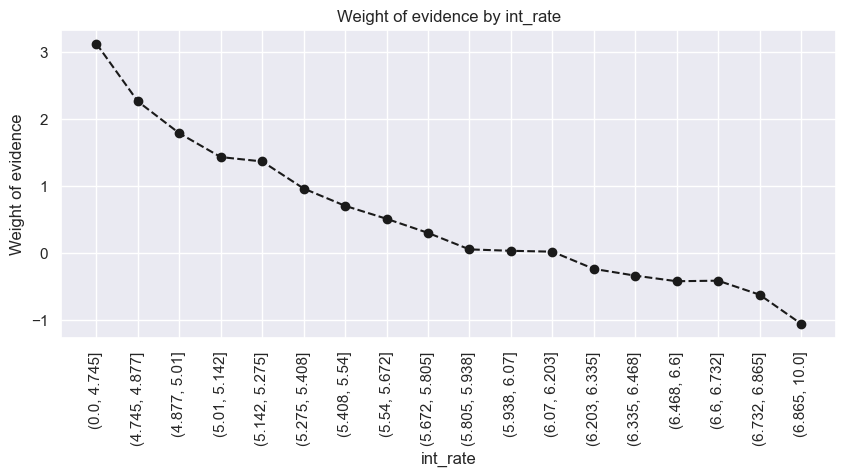

In [100]:
plot_by_woe(int_rate_table, rotation = 90)

**Coarse classing.** We group `int_rate` into seven categories. The intervals up to 5.01 are merged, because the lowest ones contain very few loans and defaults.

In [101]:
bins = [0, 5.01, 5.408, 5.805, 6.203, 6.468, 6.865, 10]
int_rate_fine = pd.cut(df_inputs_prepr['int_rate'], bins).to_frame('int_rate')
int_rate_table = woe_ordered(int_rate_fine, 'int_rate', df_targets_prepr)
int_rate_table

,int_rate,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,"(0.0, 5.01]",28162,170,27992,0.143703,0.015088,0.151549,2.306988,NaN,0.006037,NaN,0.624876
1,"(5.01, 5.408]",19139,347,18792,0.097661,0.030798,0.101740,1.194974,1.112014,0.018131,0.012094,0.624876
2,"(5.408, 5.805]",30265,1115,29150,0.154435,0.098962,0.157818,0.466713,0.728261,0.036841,0.018711,0.624876
3,"(5.805, 6.203]",42658,2374,40284,0.217673,0.210704,0.218098,0.034491,0.432222,0.055652,0.018811,0.624876
4,"(6.203, 6.468]",31077,2345,28732,0.158578,0.208130,0.155555,-0.291161,0.325652,0.075458,0.019806,0.624876
5,"(6.468, 6.865]",29579,2656,26923,0.150934,0.235733,0.145761,-0.480728,0.189566,0.089793,0.014336,0.624876
6,"(6.865, 10.0]",15093,2260,12833,0.077016,0.200586,0.069478,-1.060232,0.579505,0.149738,0.059945,0.624876


**Result.** IV of `int_rate` = 0.625 (strong). The WoE decreases monotonically with `int_rate`. The variable is kept; the reference category is (6.865, 10].

In [102]:
df_inputs_prepr['int_rate:<=5.01'] = np.where(df_inputs_prepr['int_rate'] <= 5.01, 1, 0)
df_inputs_prepr['int_rate:5.01-5.408'] = np.where((df_inputs_prepr['int_rate'] > 5.01) & (df_inputs_prepr['int_rate'] <= 5.408), 1, 0)
df_inputs_prepr['int_rate:5.408-5.805'] = np.where((df_inputs_prepr['int_rate'] > 5.408) & (df_inputs_prepr['int_rate'] <= 5.805), 1, 0)
df_inputs_prepr['int_rate:5.805-6.203'] = np.where((df_inputs_prepr['int_rate'] > 5.805) & (df_inputs_prepr['int_rate'] <= 6.203), 1, 0)
df_inputs_prepr['int_rate:6.203-6.468'] = np.where((df_inputs_prepr['int_rate'] > 6.203) & (df_inputs_prepr['int_rate'] <= 6.468), 1, 0)
df_inputs_prepr['int_rate:6.468-6.865'] = np.where((df_inputs_prepr['int_rate'] > 6.468) & (df_inputs_prepr['int_rate'] <= 6.865), 1, 0)
df_inputs_prepr['int_rate:>6.865'] = np.where(df_inputs_prepr['int_rate'] > 6.865, 1, 0)

In [103]:
int_rate_cols = ['int_rate:<=5.01', 'int_rate:5.01-5.408', 'int_rate:5.408-5.805', 'int_rate:5.805-6.203', 'int_rate:6.203-6.468', 'int_rate:6.468-6.865', 'int_rate:>6.865']
df_inputs_prepr[int_rate_cols].sum(axis = 1).value_counts()

1    195973
Name: count, dtype: int64

In [104]:
ref_categories['int_rate'] = 'int_rate:>6.865'

#### 8. `orig_loan_term`

In [105]:
orig_loan_term_fine = pd.cut(df_inputs_prepr['orig_loan_term'], 50).to_frame('orig_loan_term')
orig_loan_term_table = woe_ordered(orig_loan_term_fine, 'orig_loan_term', df_targets_prepr)
orig_loan_term_table

,orig_loan_term,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,"(59.58, 68.4]",7,0,7,0.000036,0.000000,0.000038,inf,NaN,0.000000,NaN,inf
1,"(76.8, 85.2]",1,0,1,0.000005,0.000000,0.000005,inf,NaN,0.000000,0.000000,inf
2,"(93.6, 102.0]",4,0,4,0.000020,0.000000,0.000022,inf,NaN,0.000000,0.000000,inf
3,"(102.0, 110.4]",1,0,1,0.000005,0.000000,0.000005,inf,NaN,0.000000,0.000000,inf
4,"(118.8, 127.2]",1768,7,1761,0.009022,0.000621,0.009534,2.730840,inf,0.003959,0.003959,inf
5,"(127.2, 135.6]",13,0,13,0.000066,0.000000,0.000070,inf,inf,0.000000,0.003959,inf
6,"(135.6, 144.0]",56,0,56,0.000286,0.000000,0.000303,inf,NaN,0.000000,0.000000,inf
7,"(144.0, 152.4]",14,0,14,0.000071,0.000000,0.000076,inf,NaN,0.000000,0.000000,inf
8,"(152.4, 160.8]",62,0,62,0.000316,0.000000,0.000336,inf,NaN,0.000000,0.000000,inf
9,"(160.8, 169.2]",46,0,46,0.000235,0.000000,0.000249,inf,NaN,0.000000,0.000000,inf


C:\Users\keram\AppData\Local\Temp\ipykernel_9292\3094246576.py:2: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  x = table.iloc[:, 0].astype(object).fillna('missing').astype(str)


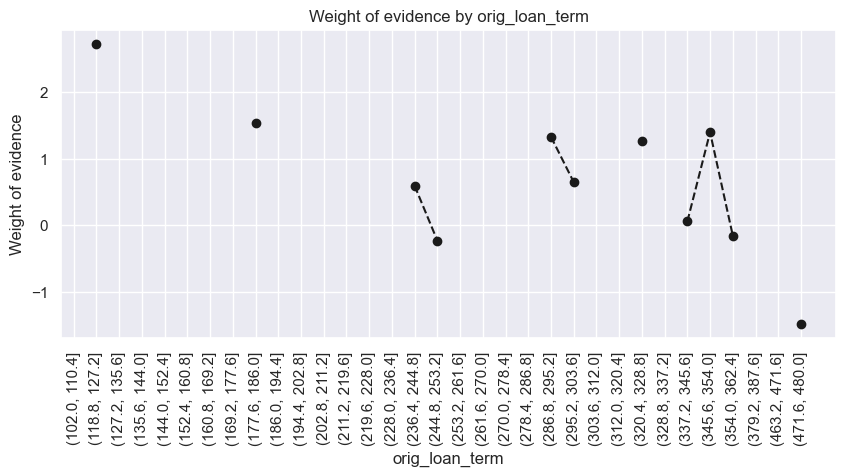

In [106]:
plot_by_woe(orig_loan_term_table, rotation = 90)

**Coarse classing.** The loan terms cluster around a few standard values, and most intervals contain very few loans. We group them into three categories: up to 186 months, 186 to 354 months and above 354 months.

In [107]:
bins = [0, 186, 354, 500]
orig_loan_term_fine = pd.cut(df_inputs_prepr['orig_loan_term'], bins).to_frame('orig_loan_term')
orig_loan_term_table = woe_ordered(orig_loan_term_fine, 'orig_loan_term', df_targets_prepr)
orig_loan_term_table

,orig_loan_term,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,"(0, 186]",27020,331,26689,0.137876,0.029378,0.144494,1.593001,NaN,0.012250,NaN,0.220464
1,"(186, 354]",9519,297,9222,0.048573,0.026360,0.049928,0.638728,0.954273,0.031201,0.018951,0.220464
2,"(354, 500]",159434,10639,148795,0.813551,0.944262,0.805578,-0.158844,0.797572,0.066730,0.035529,0.220464


**Result.** IV of `orig_loan_term` = 0.220 (medium). The WoE decreases monotonically with the term. The variable is kept; the reference category is (354, 500].

In [108]:
df_inputs_prepr['orig_loan_term:<=186'] = np.where(df_inputs_prepr['orig_loan_term'] <= 186, 1, 0)
df_inputs_prepr['orig_loan_term:186-354'] = np.where((df_inputs_prepr['orig_loan_term'] > 186) & (df_inputs_prepr['orig_loan_term'] <= 354), 1, 0)
df_inputs_prepr['orig_loan_term:>354'] = np.where(df_inputs_prepr['orig_loan_term'] > 354, 1, 0)

In [109]:
orig_loan_term_cols = ['orig_loan_term:<=186', 'orig_loan_term:186-354', 'orig_loan_term:>354']
df_inputs_prepr[orig_loan_term_cols].sum(axis = 1).value_counts()

1    195973
Name: count, dtype: int64

In [110]:
ref_categories['orig_loan_term'] = 'orig_loan_term:>354'

### 2.4.4 Summary

| Variable | IV | Decision |
|---|---|---|
| `credit_score` | 0.635 | kept |
| `int_rate` | 0.625 | kept |
| `ltv` | 0.530 | kept |
| `cltv` | 0.498 | kept |
| `property_state` | 0.320 | kept |
| `orig_loan_term` | 0.220 | kept |
| `channel` | 0.204 | kept |
| `mi_pct` | 0.197 | kept |
| `dti` | 0.191 | kept |
| `num_borrowers` | 0.123 | kept |
| `property_type` | 0.026 | kept |
| `loan_purpose` | 0.0198 | dropped (IV < 0.02) |
| `super_conforming` | 0.018 | dropped (IV < 0.02) |
| `occupancy_status` | 0.017 | dropped (IV < 0.02) |
| `orig_upb` | 0.017 | dropped (IV < 0.02) |
| `first_time_homebuyer` | 0.006 | dropped (IV < 0.02) |
| `num_units` | 0.003 | dropped (IV < 0.02) |
| `harp_indicator` | 0.002 | dropped (IV < 0.02) |
| `prepay_penalty` | 0.001 | dropped (IV < 0.02) |
| `seller_name` | – | excluded (see 2.4.2) |
| `msa` | – | excluded (see 2.4.2) |
| `postal_code` | – | excluded (see 2.4.2) |

Of the 22 candidate inputs, 11 are kept, 8 are dropped because of a low IV and 3 are excluded without computing their IV.

### 2.4.5 Check of the dummy variables

In [111]:
ref_categories

{'channel': 'channel:T',
 'property_state': 'property_state:1',
 'property_type': 'property_type:MH_CO',
 'num_borrowers': 'num_borrowers:1',
 'credit_score': 'credit_score:<=650',
 'mi_pct': 'mi_pct:>27',
 'cltv': 'cltv:>80',
 'dti': 'dti:>44.52',
 'ltv': 'ltv:>82.16',
 'int_rate': 'int_rate:>6.865',
 'orig_loan_term': 'orig_loan_term:>354'}

In [112]:
dummy_cols = [col for col in df_inputs_prepr.columns if ':' in col]
len(dummy_cols)

# Expected output 54 dummies

54

In [113]:
# For each variable on the train set,
# the dummies of every loan must add up to 1 (each loan belongs to exactly one category).

for variable in ref_categories:
    cols = [col for col in dummy_cols if col.startswith(variable + ':')]
    print(variable, len(cols), df_inputs_prepr[cols].sum(axis = 1).unique())

channel 4 [1]
property_state 7 [1]
property_type 3 [1]
num_borrowers 2 [1]
credit_score 8 [1]
mi_pct 3 [1]
cltv 6 [1]
dti 5 [1]
ltv 6 [1]
int_rate 7 [1]
orig_loan_term 3 [1]


### 2.4.6 Dummy variables for the test set

We now create the same dummy variables for the test set, using exactly the categories learned from the training set, so that the model can be applied to both sets.

To avoid repeating the code, we put it in a function. The function takes a dataframe of loans with the initial columns (before the dummies were created) and returns a dataframe with the same loans as rows and only the dummy variables as columns.

In [114]:
def create_dummies(df):
    dummies = pd.DataFrame(index = df.index)

    for category in ['T', 'R', 'B', 'C']:
        dummies[f'channel:{category}'] = np.where(df['channel'] == category, 1, 0)

    for category, states in property_state_groups.items():
        dummies[f'property_state:{category}'] = np.where(df['property_state'].isin(states), 1, 0)

    for category, values in property_type_groups.items():
        dummies[f'property_type:{category}'] = np.where(df['property_type'].fillna('SF').isin(values), 1, 0)

    for category in [1, 2]:
        dummies[f'num_borrowers:{category}'] = np.where(df['num_borrowers'].fillna(2.0) == category, 1, 0)

    dummies['credit_score:<=650'] = np.where(df['credit_score'] <= 650, 1, 0)
    dummies['credit_score:651-690'] = np.where((df['credit_score'] > 650) & (df['credit_score'] <= 690), 1, 0)
    dummies['credit_score:691-710'] = np.where((df['credit_score'] > 690) & (df['credit_score'] <= 710), 1, 0)
    dummies['credit_score:711-740'] = np.where((df['credit_score'] > 710) & (df['credit_score'] <= 740), 1, 0)
    dummies['credit_score:741-760'] = np.where(((df['credit_score'] > 740) & (df['credit_score'] <= 760)) | (df['credit_score'].isnull()), 1, 0)
    dummies['credit_score:761-780'] = np.where((df['credit_score'] > 760) & (df['credit_score'] <= 780), 1, 0)
    dummies['credit_score:781-800'] = np.where((df['credit_score'] > 780) & (df['credit_score'] <= 800), 1, 0)
    dummies['credit_score:>800'] = np.where(df['credit_score'] > 800, 1, 0)

    dummies['mi_pct:<=6'] = np.where((df['mi_pct'] <= 6) | (df['mi_pct'].isnull()), 1, 0)
    dummies['mi_pct:7-27'] = np.where((df['mi_pct'] > 6) & (df['mi_pct'] <= 27), 1, 0)
    dummies['mi_pct:>27'] = np.where(df['mi_pct'] > 27, 1, 0)

    dummies['cltv:<=40'] = np.where(df['cltv'] <= 40, 1, 0)
    dummies['cltv:41-50'] = np.where((df['cltv'] > 40) & (df['cltv'] <= 50), 1, 0)
    dummies['cltv:51-60'] = np.where((df['cltv'] > 50) & (df['cltv'] <= 60), 1, 0)
    dummies['cltv:61-65'] = np.where((df['cltv'] > 60) & (df['cltv'] <= 65), 1, 0)
    dummies['cltv:66-80'] = np.where(((df['cltv'] > 65) & (df['cltv'] <= 80)) | (df['cltv'].isnull()), 1, 0)
    dummies['cltv:>80'] = np.where(df['cltv'] > 80, 1, 0)

    dummies['dti:<=21.48'] = np.where(df['dti'] <= 21.48, 1, 0)
    dummies['dti:21.48-29.16'] = np.where((df['dti'] > 21.48) & (df['dti'] <= 29.16), 1, 0)
    dummies['dti:29.16-36.84'] = np.where(((df['dti'] > 29.16) & (df['dti'] <= 36.84)) | (df['dti'].isnull()), 1, 0)
    dummies['dti:36.84-44.52'] = np.where((df['dti'] > 36.84) & (df['dti'] <= 44.52), 1, 0)
    dummies['dti:>44.52'] = np.where(df['dti'] > 44.52, 1, 0)

    dummies['ltv:<=34.56'] = np.where(df['ltv'] <= 34.56, 1, 0)
    dummies['ltv:34.56-48.84'] = np.where((df['ltv'] > 34.56) & (df['ltv'] <= 48.84), 1, 0)
    dummies['ltv:48.84-58.36'] = np.where((df['ltv'] > 48.84) & (df['ltv'] <= 58.36), 1, 0)
    dummies['ltv:58.36-67.88'] = np.where((df['ltv'] > 58.36) & (df['ltv'] <= 67.88), 1, 0)
    dummies['ltv:67.88-82.16'] = np.where(((df['ltv'] > 67.88) & (df['ltv'] <= 82.16)) | (df['ltv'].isnull()), 1, 0)
    dummies['ltv:>82.16'] = np.where(df['ltv'] > 82.16, 1, 0)

    dummies['int_rate:<=5.01'] = np.where(df['int_rate'] <= 5.01, 1, 0)
    dummies['int_rate:5.01-5.408'] = np.where((df['int_rate'] > 5.01) & (df['int_rate'] <= 5.408), 1, 0)
    dummies['int_rate:5.408-5.805'] = np.where((df['int_rate'] > 5.408) & (df['int_rate'] <= 5.805), 1, 0)
    dummies['int_rate:5.805-6.203'] = np.where((df['int_rate'] > 5.805) & (df['int_rate'] <= 6.203), 1, 0)
    dummies['int_rate:6.203-6.468'] = np.where((df['int_rate'] > 6.203) & (df['int_rate'] <= 6.468), 1, 0)
    dummies['int_rate:6.468-6.865'] = np.where((df['int_rate'] > 6.468) & (df['int_rate'] <= 6.865), 1, 0)
    dummies['int_rate:>6.865'] = np.where(df['int_rate'] > 6.865, 1, 0)

    dummies['orig_loan_term:<=186'] = np.where(df['orig_loan_term'] <= 186, 1, 0)
    dummies['orig_loan_term:186-354'] = np.where((df['orig_loan_term'] > 186) & (df['orig_loan_term'] <= 354), 1, 0)
    dummies['orig_loan_term:>354'] = np.where(df['orig_loan_term'] > 354, 1, 0)

    return dummies

Now we check that the function works correctly.

In [115]:
# We work on the train set:

# From all columns of df_inputs_prepr, we keep those that correspond to the dummies built by hand in 2.4
dummy_cols = [col for col in df_inputs_prepr.columns if ':' in col]

# We apply the function to loan_data_inputs_train to obtain the dummies
train_dummies = create_dummies(loan_data_inputs_train)

# We compare the dummies produced by the function with those built by hand in 2.4
# (selecting dummy_cols puts the columns in the same order and leaves out the initial columns)
train_dummies[dummy_cols].equals(df_inputs_prepr[dummy_cols])

True

The result is `True`: the function reproduces exactly the dummies created by hand for the training set.

In [116]:
# We work on the test set:

# Since we previously cheched the function, we apply it on loan_data_inputs_test
test_dummies = create_dummies(loan_data_inputs_test)

# We check the shape of the test set. Expected output 54 dummies
test_dummies.shape

(48994, 54)

In [117]:
# For each variable on the test set,
# the dummies of every loan must add up to 1 (each loan belongs to exactly one category).
for variable in ref_categories:
    cols = [col for col in test_dummies.columns if col.startswith(variable + ':')]
    print(variable, len(cols), test_dummies[cols].sum(axis = 1).unique())

channel 4 [1]
property_state 7 [1]
property_type 3 [1]
num_borrowers 2 [1]
credit_score 8 [1]
mi_pct 3 [1]
cltv 6 [1]
dti 5 [1]
ltv 6 [1]
int_rate 7 [1]
orig_loan_term 3 [1]


We check that the function reproduces the training dummies exactly, and then apply it to the test set. In the test set, every loan belongs to exactly one category of each variable.

## 2.5 Model

**Model.** We model the probability of default with a logistic regression. For a loan with input vector $x$ (the dummy variables),

$$\text{PD}(x) = P(\text{default} = 1 \mid x) = \frac{1}{1 + e^{-(\beta_0 + \beta^\top x)}}, \qquad \log\frac{\text{PD}(x)}{1 - \text{PD}(x)} = \beta_0 + \beta^\top x.$$

Each coefficient $\beta_j$ is the change in the log-odds of default, all else being equal, when the loan belongs to the corresponding category instead of the reference category of its variable. We estimate the coefficients by maximum likelihood on the training set, and denote the estimates by $\hat\beta_j$. The predicted probability of default is then

$$\widehat{\text{PD}}(x) = \frac{1}{1 + e^{-(\hat\beta_0 + \hat\beta^\top x)}}.$$

**Inputs.** The inputs of the model are the dummy variables of Section 2.4, without the reference category of each variable. The reference categories are removed because the dummies of a variable add up to 1 for every loan, which is the constant column of the intercept, so they would be linearly dependent on it.

In [118]:
inputs_train = train_dummies.drop(columns = list(ref_categories.values()))
inputs_test = test_dummies.drop(columns = list(ref_categories.values()))
inputs_train.shape

(195973, 43)

### 2.5.1 Fit the model

We fit the logistic regression on the training set with `statsmodels`. It computes the maximum likelihood estimates (without a penalty on the coefficients) by Newton's method, and also gives the standard errors and the p-values used in Section 2.5.3. We add a column of ones to the inputs, which corresponds to the intercept $\beta_0$.

In [119]:
import statsmodels.api as sm

logit_model = sm.Logit(loan_data_targets_train, sm.add_constant(inputs_train))
logit_results = logit_model.fit()

Optimization terminated successfully.
         Current function value: 0.174047
         Iterations 10


### 2.5.2 Coefficients

The table below shows the intercept and the coefficient of each dummy variable. Consider two loans that belong to the same categories of all variables, except for one variable, in which the first loan belongs to the reference category and the second to another category. A positive coefficient of that category means that the second loan has a higher probability of default than the first, and a negative coefficient that it has a lower one.

Since the reference category of each variable is the one with the lowest WoE (the riskiest), we expect the coefficients to be negative. This need not hold for every coefficient: the WoE is computed for each variable separately and ignores the other variables, whereas the coefficients are estimated jointly and therefore take into account the correlations between the variables (such as the one between `ltv` and `cltv`), which can change the sign of a coefficient.

In [120]:
summary_table = pd.DataFrame({'Feature name': logit_results.params.index, 'Coefficients': logit_results.params.values})
summary_table

,Feature name,Coefficients
0,const,1.453767
1,channel:R,-0.319393
2,channel:B,-0.480227
3,channel:C,-0.746199
4,property_state:2,-0.839345
5,property_state:3,-0.821315
6,property_state:4,-1.288118
7,property_state:5,-1.613218
8,property_state:6,-1.777808
9,property_state:7,-2.362166


All coefficients are negative, as expected, except for `mi_pct:<=6` ($+0.068$, not significant, see Section 2.5.3). Within each variable the coefficients follow the order of the WoE, except for `property_state`, where categories 2 and 3 have almost the same coefficient, and for `mi_pct`, where the sign of `mi_pct:<=6` puts it above the reference category.

### 2.5.3 p-values

For each coefficient we test the null hypothesis that it is zero, i.e. that, all else being equal, the category does not differ from the reference category. A p-value below 0.05 leads us to reject the hypothesis: the category differs significantly from the reference category. A larger p-value means that we cannot reject it: the data give no evidence that the category differs from the reference category, and we regard the category as not adding information to the model.

In [121]:
logit_results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                default   No. Observations:               195973
Model:                          Logit   Df Residuals:                   195929
Method:                           MLE   Df Model:                           43
Date:                Tue, 10 Nov 2026   Pseudo R-squ.:                  0.2089
Time:                        17:21:07   Log-Likelihood:                -34109.
converged:                       True   LL-Null:                       -43116.
Covariance Type:            nonrobust   LLR p-value:                     0.000
==========================================================================================
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                      1.4538      0.057     25.381      0.000       1.342       1.566
channel:R                 -0.3194      0.022    -14.374      0.000      -0.363      -0.276
channel:B                 -0.4802      0.059     -8.100      0.000      -0.596      -0.364
channel:C                 -0.7462      0.057    -13.188      0.000      -0.857      -0.635
property_state:2          -0.8393      0.041    -20.527      0.000      -0.919      -0.759
property_state:3          -0.8213      0.034    -23.968      0.000      -0.888      -0.754
property_state:4          -1.2881      0.033    -39.092      0.000      -1.353      -1.224
property_state:5          -1.6132      0.034    -47.434      0.000      -1.680      -1.547
property_state:6          -1.7778      0.045    -39.899      0.000      -1.865      -1.690
property_state:7          -2.3622      0.059    -40.169      0.000      -2.477      -2.247
property_type:SF          -0.1592      0.033     -4.836      0.000      -0.224      -0.095
property_type:PU_CP       -0.3330      0.041     -8.063      0.000      -0.414      -0.252
num_borrowers:2           -0.5838      0.021    -27.403      0.000      -0.626      -0.542
credit_score:651-690      -0.3457      0.032    -10.837      0.000      -0.408      -0.283
credit_score:691-710      -0.6198      0.038    -16.487      0.000      -0.693      -0.546
credit_score:711-740      -0.8675      0.035    -24.529      0.000      -0.937      -0.798
credit_score:741-760      -1.1077      0.041    -27.036      0.000      -1.188      -1.027
credit_score:761-780      -1.4964      0.045    -33.406      0.000      -1.584      -1.409
credit_score:781-800      -1.8141      0.052    -35.160      0.000      -1.915      -1.713
credit_score:>800         -1.9464      0.074    -26.480      0.000      -2.090      -1.802
mi_pct:<=6                 0.0675      0.090      0.749      0.454      -0.109       0.244
mi_pct:7-27               -0.1323      0.041     -3.258      0.001      -0.212      -0.053
cltv:<=40                 -1.2463      0.202     -6.162      0.000      -1.643      -0.850
cltv:41-50                -0.9899      0.147     -6.751      0.000      -1.277      -0.703
cltv:51-60                -0.8128      0.097     -8.348      0.000      -1.004      -0.622
cltv:61-65                -0.5945      0.084     -7.049      0.000      -0.760      -0.429
cltv:66-80                -0.3798      0.033    -11.590      0.000      -0.444      -0.316
dti:<=21.48               -0.5603      0.046    -12.264      0.000      -0.650      -0.471
dti:21.48-29.16           -0.5032      0.035    -14.224      0.000      -0.573      -0.434
dti:29.16-36.84           -0.2490      0.029     -8.637      0.000      -0.305      -0.192
dti:36.84-44.52           -0.1232      0.027     -4.539      0.000      -0.176      -0.070
ltv:<=34.56               -1.8407      0.254     -7.252      0.000      -2.338      -1.343
ltv:34.56-48.84           -1.2858      0.174     -7.377 

We use the 5% significance level, applied to each original variable: a variable is kept if at least one of its dummies is significant, and it is removed if none is. Dropping a single dummy would merge its category with the reference category, a choice that is not supported by the data. All p-values are below 0.05, except for `mi_pct:<=6` (p-value 0.454). Since `mi_pct:7-27` is significant, we keep both dummies of `mi_pct` and the model stays as it is.

## 2.6 Evaluation

We evaluate the model on the test set, which was not used to fit it. We apply the model to the inputs of each loan in the test set to obtain its probability of default (PD), and we measure how well these PDs separate the loans that defaulted from those that did not.

In [122]:
PD_test = logit_results.predict(sm.add_constant(inputs_test))
PD_test.describe()

count    48994.000000
mean         0.057934
std          0.083389
min          0.000023
25%          0.007028
50%          0.025503
75%          0.073293
max          0.790927
dtype: float64

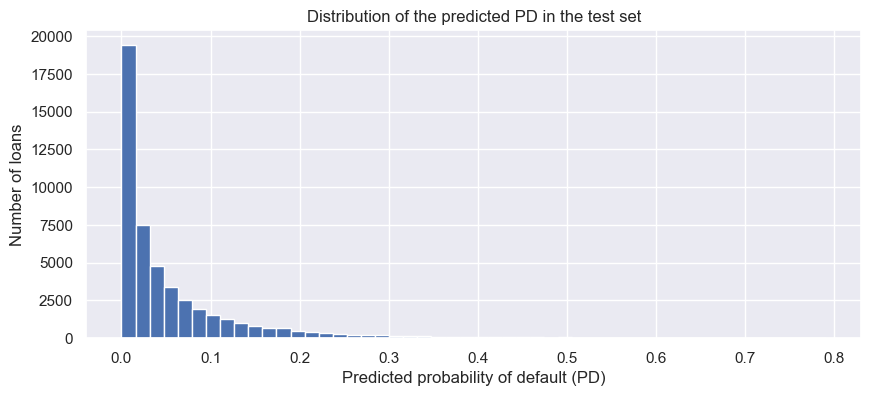

In [123]:
plt.figure(figsize = (10, 4))
plt.hist(PD_test, bins = 50)
plt.xlabel('Predicted probability of default (PD)')
plt.ylabel('Number of loans')
plt.title('Distribution of the predicted PD in the test set')
plt.show()

### 2.6.1 ROC curve and AUC

For a cutoff $c$ of the PD, we classify a loan as "default" if its PD is above $c$. The ROC curve plots, for every cutoff, the share of defaulted loans that are detected (true positive rate) against the share of non-defaulted loans that are wrongly flagged (false positive rate). The AUC is the area under the curve: it is the probability that a randomly chosen defaulted loan has a higher PD than a randomly chosen non-defaulted loan. A random model has AUC 0.5. The Gini coefficient is 2 · AUC − 1.

In [124]:
from sklearn.metrics import roc_curve, roc_auc_score
fpr, tpr, thresholds = roc_curve(loan_data_targets_test, PD_test)

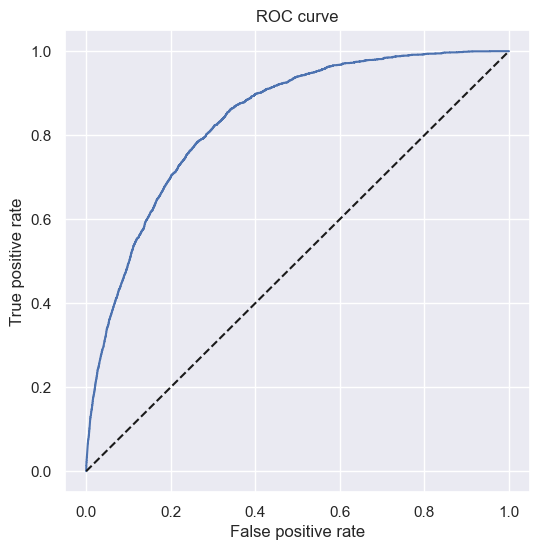

In [125]:
plt.figure(figsize = (6, 6))
plt.plot(fpr, tpr)
plt.plot(fpr, fpr, linestyle = '--', color = 'k')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC curve')
plt.show()

In [126]:
AUC = roc_auc_score(loan_data_targets_test, PD_test)
Gini = 2 * AUC - 1
AUC, Gini

(0.8381898065990758, 0.6763796131981517)

The AUC on the test set is 0.838 and the Gini coefficient is 0.676: the model gives a higher PD to a loan that defaulted than to one that did not in about 84% of the pairs.

We now proceed with the train set.

In [127]:
PD_train = logit_results.predict(sm.add_constant(inputs_train))
AUC_train = roc_auc_score(loan_data_targets_train, PD_train)
AUC_train

0.8404618369618102

**How to read the AUC.** The AUC is the probability that a randomly chosen defaulted loan has a higher PD than a randomly chosen non-defaulted loan. A model without any discriminatory power has AUC 0.5. As a rule of thumb (Hosmer and Lemeshow), AUC between 0.7 and 0.8 is acceptable, between 0.8 and 0.9 excellent, and above 0.9 outstanding. For a PD model, a value above 0.9 should be checked for leakage (inputs that contain information about the outcome). The Gini coefficient $2 \cdot \text{AUC} - 1$ takes values between 0 and 1, and the same thresholds correspond to 0.4, 0.6 and 0.8. These thresholds are only conventions: what is attainable depends on the portfolio and on the variables available.

**Overfitting.** A model overfits when it has learned features of the training set that do not hold in general. We detect it by comparing the AUC on the training set and on the test set. The training AUC is always slightly higher, since the coefficients were fitted on that data. A difference of a few hundredths is normal, while a much larger one (for example above 0.05) means that the model does not generalize.

### 2.6.2 Kolmogorov-Smirnov statistic

The KS statistic is the maximum distance between the cumulative distributions of the PD among the defaulted and the non-defaulted loans. Equivalently, it is the maximum of the difference between the true positive rate and the false positive rate over all the cutoffs, i.e. the maximum vertical distance between the ROC curve and the diagonal. It is 0 for a model without discriminatory power and 1 for a perfect model.

In [128]:
KS = max(tpr - fpr)
KS

np.float64(0.521101358004866)

The KS statistic on the test set is 0.521. Together with the AUC (0.838) and the Gini coefficient (0.676), this indicates a good discriminatory power of the model.

### 2.6.3 Calibration

### 2.6.3 Calibration

The AUC, the Gini coefficient and the KS statistic only measure the ranking of the loans by PD. Since the expected loss is computed as PD × LGD × EAD, the values of the PD must also be accurate: among the loans with a predicted PD of 5%, about 5% should default.

We sort the loans of the test set by their predicted PD and split them into ten groups of equal size (deciles). In each group we compute the mean predicted PD and the observed default rate, i.e. the share of loans of the group that actually defaulted, and we compare them.

In [129]:
calibration = pd.DataFrame({'PD': PD_test, 'default': loan_data_targets_test})
calibration['decile'] = pd.qcut(calibration['PD'], 10, labels = False)

In [130]:
calibration_table = calibration.groupby('decile').agg(n_obs = ('default', 'count'), mean_PD = ('PD', 'mean'), default_rate = ('default', 'mean'))
calibration_table

,n_obs,mean_PD,default_rate
decile,,,
0,4900,0.001022,0.000816
1,4899,0.003357,0.003878
2,4899,0.007093,0.006940
3,4900,0.012606,0.009184
4,4899,0.020522,0.022045
5,4899,0.031976,0.027353
6,4901,0.048528,0.051010
7,4898,0.074103,0.077787
8,4899,0.119404,0.125536


In every decile the mean predicted PD is close to the observed default rate, so the model is well calibrated on the test set. The highest decile contains about 44% of all the defaults of the test set.

## 2.7 Scorecard: Converting the model into a score

**Motivation:** For each borrower the model gives the *log odds* of default $z=\hat\beta_0+\sum_{\text{active}}\hat\beta_j$, and from them the probability $\hat p=\dfrac{1}{1+e^{-z}}$ of default. To be used in practice by people who do not know the model, it needs a simpler form: a ***scorecard***, i.e. a table that gives **points** for each category of each variable. The final *credit score* of a borrower is obtained by **adding the points of the categories he belongs to**, without exponentials, logarithms or knowledge of the coefficients.

We want the score to take values in a fixed interval, e.g. $[300,850]$ (as FICO), with a higher score meaning a lower probability of default.

**How it is done:**

1. Every borrower belongs to **exactly one** category of each original variable (including the *reference category*, with coefficient $0$). So, if $V$ is the set of original variables and $\hat\beta_j$, $j\in v$, are the coefficients of the categories of the variable $v$, the minimum and the maximum possible $z$ are
$$
S_{\min}=\hat\beta_0+\sum_{v\in V}\min_{j\in v}\hat\beta_j,\qquad
S_{\max}=\hat\beta_0+\sum_{v\in V}\max_{j\in v}\hat\beta_j .
$$
2. We map $z$ to $[300,850]$ linearly, through the line that passes through the points $(S_{\min},850)$ and $(S_{\max},300)$. Its slope is
$$
\lambda=\frac{300-850}{S_{\max}-S_{\min}}<0,
$$
so
$$
\text{score}(z)=850+\lambda\,(z-S_{\min}).
$$
3. Substituting $z=\hat\beta_0+\sum_{\text{active}}\hat\beta_j$, the score is written as a **sum of points per category**:
$$
\text{score}=\underbrace{850+\lambda(\hat\beta_0-S_{\min})}_{\text{the same for every borrower}}+\sum_{\text{active}}\underbrace{\lambda\,\hat\beta_j}_{\text{points of category }j} .
$$
The points of the category $j$ -- i.e. its contribution to the sum above -- are $\lambda \hat\beta_j$. Consequently, the points of the *intercept* $\hat\beta_0$ -- i.e. its contribution to the sum above -- are $850+\lambda(\hat\beta_0-S_{\min})$.

4. We round the points to integers. We check below that the minimum and the maximum possible scores are still exactly $300$ and $850$, respectively.

Since $\lambda < 0$, a higher $z$ (higher probability of default) gives a lower score. The map is linear, so it preserves the ranking of the loans (the AUC, the Gini coefficient and the KS statistic are unchanged up to the rounding of the points), and the PD of a loan can be recovered approximately from its score, by the inverse of the linear map (the rounding of the points makes the recovery inexact).

In [131]:
df_scorecard = pd.DataFrame({'Feature name': logit_results.params.index, 'Coefficients': logit_results.params.values})
df_scorecard

,Feature name,Coefficients
0,const,1.453767
1,channel:R,-0.319393
2,channel:B,-0.480227
3,channel:C,-0.746199
4,property_state:2,-0.839345
5,property_state:3,-0.821315
6,property_state:4,-1.288118
7,property_state:5,-1.613218
8,property_state:6,-1.777808
9,property_state:7,-2.362166


In [132]:
# Add reference categories
df_ref_categories = pd.DataFrame({'Feature name': list(ref_categories.values()), 'Coefficients': 0})
df_scorecard = pd.concat([df_scorecard, df_ref_categories]).reset_index(drop = True)
df_scorecard['Original feature name'] = df_scorecard['Feature name'].str.split(':').str[0]
df_scorecard

,Feature name,Coefficients,Original feature name
0,const,1.453767,const
1,channel:R,-0.319393,channel
2,channel:B,-0.480227,channel
3,channel:C,-0.746199,channel
4,property_state:2,-0.839345,property_state
5,property_state:3,-0.821315,property_state
6,property_state:4,-1.288118,property_state
7,property_state:5,-1.613218,property_state
8,property_state:6,-1.777808,property_state
9,property_state:7,-2.362166,property_state


**Step 1.** For each original variable, we find the smallest and the largest coefficient among its categories (the reference category counts as $0$). Their differences, summed over the variables, give $S_{\max} - S_{\min}$.

In [133]:
# Find min and max coefficient per variable
df_variables = df_scorecard[df_scorecard['Feature name'] != 'const']
min_coef = df_variables.groupby('Original feature name')['Coefficients'].min()
max_coef = df_variables.groupby('Original feature name')['Coefficients'].max()
min_coef, max_coef

(Original feature name
 channel          -0.746199
 cltv             -1.246272
 credit_score     -1.946407
 dti              -0.560267
 int_rate         -1.823213
 ltv              -1.840674
 mi_pct           -0.132315
 num_borrowers    -0.583769
 orig_loan_term   -0.754761
 property_state   -2.362166
 property_type    -0.332969
 Name: Coefficients, dtype: float64,
 Original feature name
 channel           0.000000
 cltv              0.000000
 credit_score      0.000000
 dti               0.000000
 int_rate          0.000000
 ltv               0.000000
 mi_pct            0.067494
 num_borrowers     0.000000
 orig_loan_term    0.000000
 property_state    0.000000
 property_type     0.000000
 Name: Coefficients, dtype: float64)

**Step 2.** The range is $S_{\max} - S_{\min} = \sum_{v \in V} \left(\max_{j \in v} \hat\beta_j - \min_{j \in v} \hat\beta_j\right)$, and then $\lambda = \dfrac{300 - 850}{S_{\max} - S_{\min}}$.

In [134]:
coef_range = (max_coef - min_coef).sum()
slope = (300 - 850) / coef_range
coef_range, slope

(np.float64(12.396505880029078), np.float64(-44.36734071058335))

**Step 3.** The points of each category are $\lambda\hat\beta_j$ (`slope` times the coefficient). The points of the intercept are $850 + \lambda(\hat\beta_0 - S_{\min})$.

In [135]:
# Calculate b_0, S_min, S_max
beta_0 = df_scorecard.loc[df_scorecard['Feature name'] == 'const', 'Coefficients'].values[0]
S_min = beta_0 + min_coef.sum()
S_max = beta_0 + max_coef.sum()
beta_0, S_min, S_max

(np.float64(1.453766769416051),
 np.float64(-10.875244985548148),
 np.float64(1.5212608944809318))

In [136]:
# Add the point to the scorecard
df_scorecard['Points'] = df_scorecard['Coefficients'] * slope
df_scorecard.loc[df_scorecard['Feature name'] == 'const', 'Points'] = 850 + slope * (beta_0 - S_min)
df_scorecard.head()

,Feature name,Coefficients,Original feature name,Points
0,const,1.453767,const,302.994535
1,channel:R,-0.319393,channel,14.170617
2,channel:B,-0.480227,channel,21.306391
3,channel:C,-0.746199,channel,33.106856
4,property_state:2,-0.839345,property_state,37.239501


We want integer points, so we round them.

In [137]:
df_scorecard['Points - Rounded'] = df_scorecard['Points'].round()
df_scorecard.head()

,Feature name,Coefficients,Original feature name,Points,Points - Rounded
0,const,1.453767,const,302.994535,303.0
1,channel:R,-0.319393,channel,14.170617,14.0
2,channel:B,-0.480227,channel,21.306391,21.0
3,channel:C,-0.746199,channel,33.106856,33.0
4,property_state:2,-0.839345,property_state,37.239501,37.0


Check that max points and min points are $850$ and $300$ respectively.

In [138]:
df_points = df_scorecard[df_scorecard['Feature name'] != 'const']
min_points_rounded = df_points.groupby('Original feature name')['Points - Rounded'].min()
max_points_rounded = df_points.groupby('Original feature name')['Points - Rounded'].max()

const_points_rounded = df_scorecard.loc[df_scorecard['Feature name'] == 'const', 'Points - Rounded'].values[0]

const_points_rounded + max_points_rounded.sum(), const_points_rounded + min_points_rounded.sum()

(np.float64(850.0), np.float64(300.0))

**Step 4.** The credit score of a loan is the sum of the points of its categories plus the points of the intercept. We compute it for the loans of the test set.

In [139]:
test_dummies_scorecard = test_dummies[df_scorecard['Feature name'][1:].values]
test_dummies_scorecard.shape

(48994, 54)

In [140]:
points_rounded = df_scorecard['Points - Rounded'][1:].values
scores_test = test_dummies_scorecard.dot(points_rounded) + const_points_rounded
scores_test.describe()

count    48994.000000
mean       535.942217
std         76.836579
min        308.000000
25%        480.000000
50%        529.000000
75%        587.000000
max        841.000000
dtype: float64

## 2.8 Saving the results

We save the scorecard, which is needed in the README, and the predicted PD of every loan, which is needed for the expected loss.

In [141]:
df_scorecard.to_csv('../outputs/scorecard.csv', index = False)

We also save the predicted PD and the credit score of every loan of the test set, together with the actual default flag. Since `data/` is not uploaded to GitHub, the file is saved there.

In [142]:
pd_test = pd.DataFrame({'PD': PD_test, 'score': scores_test, 'default': loan_data_targets_test})
pd_test.to_csv('../data/pd_test.csv')
pd_test.head()

,PD,score,default
186947,0.089463,470.0,0
127359,0.050861,497.0,0
150322,0.015750,550.0,0
86315,0.295068,406.0,0
58432,0.084333,474.0,0


We also save the fitted model, so that it can be applied to new loans without running the notebook again.

In [143]:
logit_results.save('../outputs/pd_model.pickle', remove_data = True)